In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/AI_Unified_Content_Verification"

os.makedirs(project_path, exist_ok=True)

print("Project folder created:")
print(project_path)

Project folder created:
/content/drive/MyDrive/AI_Unified_Content_Verification


In [ ]:
# Create folders for our project

folders = [
    "datasets/fake_news",
    "datasets/ai_text",
    "datasets/deepfake_images",
    "models",
    "results",
    "reports"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("All project folders created successfully!")

All project folders created successfully!


In [ ]:
import os

fake_news_path = os.path.join(
    project_path,
    "datasets",
    "fake_news",
    "WELFake_Dataset.csv"
)

print(fake_news_path)
print("File exists:", os.path.exists(fake_news_path))

/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/fake_news/WELFake_Dataset.csv
File exists: True


In [ ]:
import pandas as pd

wel_fake = pd.read_csv(fake_news_path)

print("Dataset loaded successfully!")
print("Shape:", wel_fake.shape)

Dataset loaded successfully!
Shape: (72134, 4)


In [ ]:
wel_fake.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [ ]:
# Create a copy for cleaning
fake_news_clean = wel_fake.copy()

In [ ]:
# Remove rows where article text is missing
fake_news_clean = fake_news_clean.dropna(subset=["text"])

In [ ]:
# Replace missing titles with an empty string
fake_news_clean["title"] = fake_news_clean["title"].fillna("")


In [ ]:
# Remove the conflicting article text
text_label_check = (
    fake_news_clean.groupby("text")["label"]
    .nunique()
)

conflicting_texts = text_label_check[
    text_label_check > 1
].index

fake_news_clean = fake_news_clean[
    ~fake_news_clean["text"].isin(conflicting_texts)
]

In [ ]:
# Remove duplicate article texts
fake_news_clean = fake_news_clean.drop_duplicates(
    subset=["text"],
    keep="first"
)

# Keep only the columns needed for our model
fake_news_clean = fake_news_clean[
    ["title", "text", "label"]
]

In [ ]:
# Reset row numbers
fake_news_clean = fake_news_clean.reset_index(drop=True)

print("Cleaned dataset shape:", fake_news_clean.shape)

Cleaned dataset shape: (62717, 3)


In [ ]:
print("Missing values:")
print(fake_news_clean.isnull().sum())

print("\nDuplicate texts:")
print(fake_news_clean["text"].duplicated().sum())

print("\nLabel distribution:")
print(fake_news_clean["label"].value_counts())

print("\nFinal shape:")
print(fake_news_clean.shape)

Missing values:
title    0
text     0
label    0
dtype: int64

Duplicate texts:
0

Label distribution:
label
0    34620
1    28097
Name: count, dtype: int64

Final shape:
(62717, 3)


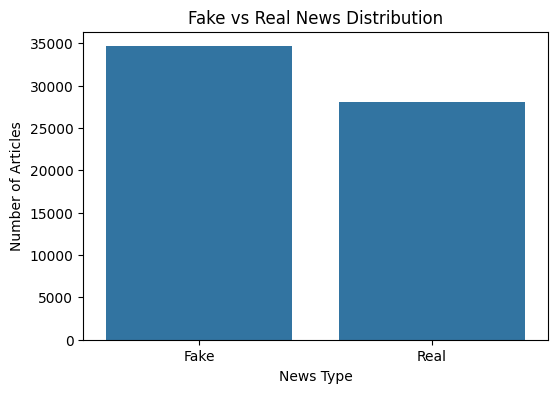

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

label_counts = fake_news_clean["label"].value_counts()

plt.figure(figsize=(6, 4))

sns.barplot(
    x=["Fake", "Real"],
    y=[
        label_counts.get(0, 0),
        label_counts.get(1, 0)
    ]
)

plt.title("Fake vs Real News Distribution")
plt.xlabel("News Type")
plt.ylabel("Number of Articles")
plt.show()

In [ ]:
fake_news_clean["text_length"] = fake_news_clean["text"].str.len()

fake_news_clean["word_count"] = (
    fake_news_clean["text"]
    .str.split()
    .str.len()
)

In [ ]:
fake_news_clean[["text_length", "word_count"]].describe()

,text_length,word_count
count,62717.000000,62717.000000
mean,3316.499609,548.992394
std,3631.823773,610.056836
min,1.000000,0.000000
25%,1477.000000,244.000000
50%,2480.000000,406.000000
75%,4132.000000,679.000000
max,142961.000000,24234.000000


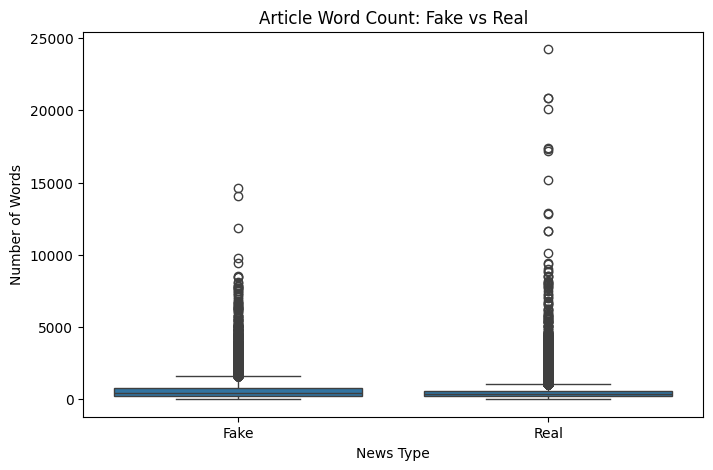

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=fake_news_clean,
    x="label",
    y="word_count"
)

plt.xticks([0, 1], ["Fake", "Real"])
plt.title("Article Word Count: Fake vs Real")
plt.xlabel("News Type")
plt.ylabel("Number of Words")

plt.show()

In [ ]:
# Combine title and article text

fake_news_clean["combined_text"] = (
    fake_news_clean["title"] + " " + fake_news_clean["text"]
)

print(fake_news_clean[["title", "combined_text", "label"]].head())

                                               title  \
0  LAW ENFORCEMENT ON HIGH ALERT Following Threat...   
1                                                      
2  UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...   
3  Bobby Jindal, raised Hindu, uses story of Chri...   
4  SATAN 2: Russia unvelis an image of its terrif...   

                                       combined_text  label  
0  LAW ENFORCEMENT ON HIGH ALERT Following Threat...      1  
1     Did they post their votes for Hillary already?      1  
2  UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...      1  
3  Bobby Jindal, raised Hindu, uses story of Chri...      0  
4  SATAN 2: Russia unvelis an image of its terrif...      1  


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# ============================================
# 1. Load original WELFake dataset
# ============================================

fake_news_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/fake_news/WELFake_Dataset.csv"

wel_fake = pd.read_csv(fake_news_path)

print("Original dataset shape:", wel_fake.shape)


# ============================================
# 2. Create copy for cleaning
# ============================================

fake_news_clean = wel_fake.copy()


# ============================================
# 3. Remove rows where article text is missing
# ============================================

fake_news_clean = fake_news_clean.dropna(subset=["text"])


# ============================================
# 4. Replace missing titles with empty string
# ============================================

fake_news_clean["title"] = fake_news_clean["title"].fillna("")


# ============================================
# 5. Remove conflicting article texts
# ============================================

text_label_check = (
    fake_news_clean.groupby("text")["label"]
    .nunique()
)

conflicting_texts = text_label_check[
    text_label_check > 1
].index

fake_news_clean = fake_news_clean[
    ~fake_news_clean["text"].isin(conflicting_texts)
]


# ============================================
# 6. Remove duplicate article texts
# ============================================

fake_news_clean = fake_news_clean.drop_duplicates(
    subset=["text"],
    keep="first"
)


# ============================================
# 7. Keep only required columns
# ============================================

fake_news_clean = fake_news_clean[
    ["title", "text", "label"]
]


# ============================================
# 8. Reset index
# ============================================

fake_news_clean = fake_news_clean.reset_index(drop=True)


# ============================================
# 9. Combine title + article text
# ============================================

fake_news_clean["combined_text"] = (
    fake_news_clean["title"] + " " +
    fake_news_clean["text"]
)


# ============================================
# 10. Verify cleaned dataset
# ============================================

print("\nCleaned dataset shape:", fake_news_clean.shape)


# ============================================
# 11. Create the SAME train/test split
# ============================================

X = fake_news_clean["combined_text"]
y = fake_news_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nSplit recreated successfully!")

Original dataset shape: (72134, 4)

Cleaned dataset shape: (62717, 4)

Training samples: 50173
Testing samples: 12544

Split recreated successfully!


In [ ]:
import joblib
import os
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

# Load the SAVED Fake News model
fake_model = joblib.load(
    os.path.join(models_dir, "fake_news_logistic_regression.pkl")
)

# Load the SAVED TF-IDF vectorizer
fake_tfidf = joblib.load(
    os.path.join(models_dir, "fake_news_tfidf.pkl")
)

print("Saved Fake News model and TF-IDF loaded successfully!")

# Transform ONLY the existing test data
X_test_tfidf = fake_tfidf.transform(X_test)

# Predict using the SAVED model
y_pred = fake_model.predict(X_test_tfidf)

# Evaluation
accuracy = accuracy_score(y_test, y_pred)

print("\n======================================")
print("       FAKE NEWS MODEL EVALUATION")
print("======================================")

print(f"\nAccuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake", "Real"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Saved Fake News model and TF-IDF loaded successfully!

       FAKE NEWS MODEL EVALUATION

Accuracy: 96.17%

Classification Report:
              precision    recall  f1-score   support

        Fake       0.96      0.97      0.97      6924
        Real       0.96      0.96      0.96      5620

    accuracy                           0.96     12544
   macro avg       0.96      0.96      0.96     12544
weighted avg       0.96      0.96      0.96     12544


Confusion Matrix:
[[6691  233]
 [ 248 5372]]


In [ ]:
import os
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

results_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/results"

os.makedirs(results_dir, exist_ok=True)

# Save test data
test_results = pd.DataFrame({
    "text": X_test,
    "actual_label": y_test,
    "predicted_label": y_pred
})

test_results.to_csv(
    os.path.join(results_dir, "fake_news_test_predictions.csv"),
    index=False
)

# Save metrics
report = classification_report(
    y_test,
    y_pred,
    target_names=["Fake", "Real"]
)

cm = confusion_matrix(y_test, y_pred)

with open(
    os.path.join(results_dir, "fake_news_evaluation.txt"),
    "w"
) as f:
    f.write("FAKE NEWS DETECTION EVALUATION\n")
    f.write("==============================\n\n")
    f.write(f"Test samples: {len(y_test)}\n")
    f.write(f"Accuracy: {accuracy * 100:.2f}%\n\n")
    f.write("Classification Report:\n")
    f.write(report)
    f.write("\nConfusion Matrix:\n")
    f.write(str(cm))

print("Evaluation results saved successfully!")
print("Saved to:", results_dir)

Evaluation results saved successfully!
Saved to: /content/drive/MyDrive/AI_Unified_Content_Verification/results


In [ ]:

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 50173
Testing samples: 12544


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [ ]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (50173, 50000)
Testing TF-IDF shape: (12544, 50000)


In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
y_pred = logistic_model.predict(X_test_tfidf)

print("Predictions completed!")
print(y_pred[:20])

Predictions completed!
[1 0 1 0 1 0 1 0 1 0 1 0 1 1 0 1 0 1 0 1]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Fake", "Real"]
    )
)

Accuracy: 0.9616549744897959

Classification Report:
              precision    recall  f1-score   support

        Fake       0.96      0.97      0.97      6924
        Real       0.96      0.96      0.96      5620

    accuracy                           0.96     12544
   macro avg       0.96      0.96      0.96     12544
weighted avg       0.96      0.96      0.96     12544



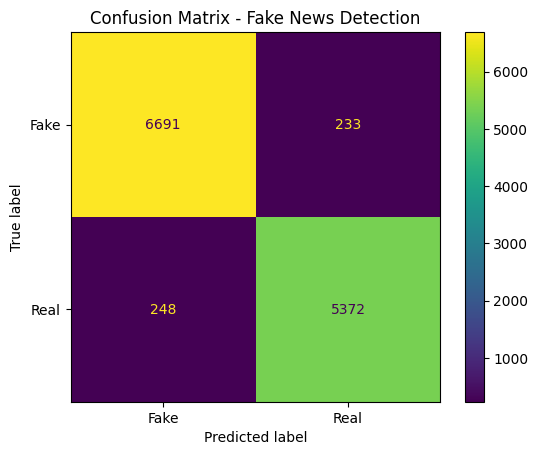

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fake", "Real"]
)

disp.plot()

plt.title("Confusion Matrix - Fake News Detection")
plt.show()

In [ ]:
import joblib
import os

model_path = os.path.join(
    project_path,
    "models",
    "fake_news_logistic_regression.pkl"
)

tfidf_path = os.path.join(
    project_path,
    "models",
    "fake_news_tfidf.pkl"
)

joblib.dump(logistic_model, model_path)
joblib.dump(tfidf, tfidf_path)

print("Model saved:", model_path)
print("TF-IDF saved:", tfidf_path)

Model saved: /content/drive/MyDrive/AI_Unified_Content_Verification/models/fake_news_logistic_regression.pkl
TF-IDF saved: /content/drive/MyDrive/AI_Unified_Content_Verification/models/fake_news_tfidf.pkl


MODULE 2 — AI-GENERATED TEXT DETECTION

In [ ]:
!pip install -q datasets

In [ ]:
!wget -O /content/HC3_all.jsonl \
https://huggingface.co/datasets/Hello-SimpleAI/HC3/resolve/main/all.jsonl

--2026-08-27 14:07:22--  https://huggingface.co/datasets/Hello-SimpleAI/HC3/resolve/main/all.jsonl
Resolving huggingface.co (huggingface.co)... 3.171.171.128, 3.171.171.104, 3.171.171.65, ...
Connecting to huggingface.co (huggingface.co)|3.171.171.128|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/63c7fbb048eff25d4e6278fb/2a1706b2815ab0610a81d84ec65d3b2a30600bb6ce39a1e8cdba86bb5379a442?response-content-disposition=inline%3B+filename*%3DUTF-8%27%27all.jsonl%3B+filename%3D%22all.jsonl%22%3B&X-Xet-Cas-Uid=public&user_id=public&Expires=1787843242&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjNjN2ZiYjA0OGVmZjI1ZDRlNjI3OGZiLzJhMTcwNmIyODE1YWIwNjEwYTgxZDg0ZWM2NWQzYjJhMzA2MDBiYjZjZTM5YTFlOGNkYmE4NmJiNTM3OWE0NDJcXD9yZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSomWC1YZXQtQ2FzLVVpZD1wdWJsaWMmdXNlcl9pZD1wdWJsaWMiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkVwb2NoVGltZSI6MTc4Nzg0MzI0Mn19f

In [ ]:
import os

print("File exists:", os.path.exists("/content/HC3_all.jsonl"))
print("File size (MB):", os.path.getsize("/content/HC3_all.jsonl") / (1024 * 1024))

File exists: True
File size (MB): 70.30758857727051


In [ ]:
import json

hc3_records = []

with open("/content/HC3_all.jsonl", "r", encoding="utf-8") as f:
    for line in f:
        hc3_records.append(json.loads(line))

print("Number of records:", len(hc3_records))

Number of records: 24322


In [ ]:
print(hc3_records[0])

{'question': 'Why is every book I hear about a " NY Times # 1 Best Seller " ? ELI5 : Why is every book I hear about a " NY Times # 1 Best Seller " ? Should n\'t there only be one " # 1 " best seller ? Please explain like I\'m five.', 'human_answers': ['Basically there are many categories of " Best Seller " . Replace " Best Seller " by something like " Oscars " and every " best seller " book is basically an " oscar - winning " book . May not have won the " Best film " , but even if you won the best director or best script , you \'re still an " oscar - winning " film . Same thing for best sellers . Also , IIRC the rankings change every week or something like that . Some you might not be best seller one week , but you may be the next week . I guess even if you do n\'t stay there for long , you still achieved the status . Hence , # 1 best seller .', "If you 're hearing about it , it 's because it was a very good or very well - publicized book ( or both ) , and almost every good or well - p

In [ ]:
print("Fields in the first record:")
print(hc3_records[0].keys())

Fields in the first record:
dict_keys(['question', 'human_answers', 'chatgpt_answers', 'index', 'source'])


In [ ]:
print("\nNumber of human answers:",
      len(hc3_records[0]["human_answers"]))

print("Number of ChatGPT answers:",
      len(hc3_records[0]["chatgpt_answers"]))


Number of human answers: 3
Number of ChatGPT answers: 1


In [ ]:
print("\nHuman answer:")
print(hc3_records[0]["human_answers"][0])

print("\nChatGPT answer:")
print(hc3_records[0]["chatgpt_answers"][0])


Human answer:
Basically there are many categories of " Best Seller " . Replace " Best Seller " by something like " Oscars " and every " best seller " book is basically an " oscar - winning " book . May not have won the " Best film " , but even if you won the best director or best script , you 're still an " oscar - winning " film . Same thing for best sellers . Also , IIRC the rankings change every week or something like that . Some you might not be best seller one week , but you may be the next week . I guess even if you do n't stay there for long , you still achieved the status . Hence , # 1 best seller .

ChatGPT answer:
There are many different best seller lists that are published by various organizations, and the New York Times is just one of them. The New York Times best seller list is a weekly list that ranks the best-selling books in the United States based on sales data from a number of different retailers. The list is published in the New York Times newspaper and is widely c

In [ ]:
import pandas as pd

ai_text_records = []

for record in hc3_records:

    # Add human-written answers
    for answer in record["human_answers"]:
        if answer and answer.strip():
            ai_text_records.append({
                "text": answer,
                "label": 0
            })

    # Add ChatGPT-generated answers
    for answer in record["chatgpt_answers"]:
        if answer and answer.strip():
            ai_text_records.append({
                "text": answer,
                "label": 1
            })

ai_text = pd.DataFrame(ai_text_records)

print("AI text dataset shape:", ai_text.shape)

AI text dataset shape: (85431, 2)


In [ ]:
ai_text.head()

,text,label
0,"Basically there are many categories of "" Best ...",0
1,"If you 're hearing about it , it 's because it...",0
2,"One reason is lots of catagories . However , h...",0
3,There are many different best seller lists tha...,1
4,salt is good for not dying in car crashes and ...,0


In [ ]:
ai_text["label"].value_counts()

,count
label,
0,58546
1,26885


In [ ]:
print("Missing values:")
print(ai_text.isnull().sum())

Missing values:
text     0
label    0
dtype: int64


In [ ]:
print("Duplicate responses:",
      ai_text["text"].duplicated().sum())

Duplicate responses: 6100


In [ ]:
text_label_check_ai = (
    ai_text.groupby("text")["label"]
    .nunique()
)

print(
    "Texts with conflicting labels:",
    (text_label_check_ai > 1).sum()
)

Texts with conflicting labels: 0


In [ ]:
print("Unique responses:",
      ai_text["text"].nunique())

Unique responses: 79331


In [ ]:
# Create a copy for cleaning
ai_text_clean = ai_text.copy()

# Remove duplicate responses
ai_text_clean = ai_text_clean.drop_duplicates(
    subset=["text"],
    keep="first"
)

# Reset index
ai_text_clean = ai_text_clean.reset_index(drop=True)

print("Cleaned AI-text dataset shape:", ai_text_clean.shape)

Cleaned AI-text dataset shape: (79331, 2)


In [ ]:
print("Missing values:")
print(ai_text_clean.isnull().sum())

print("\nDuplicate responses:")
print(ai_text_clean["text"].duplicated().sum())

print("\nLabel distribution:")
print(ai_text_clean["label"].value_counts())

print("\nFinal shape:")
print(ai_text_clean.shape)

Missing values:
text     0
label    0
dtype: int64

Duplicate responses:
0

Label distribution:
label
0    53086
1    26245
Name: count, dtype: int64

Final shape:
(79331, 2)


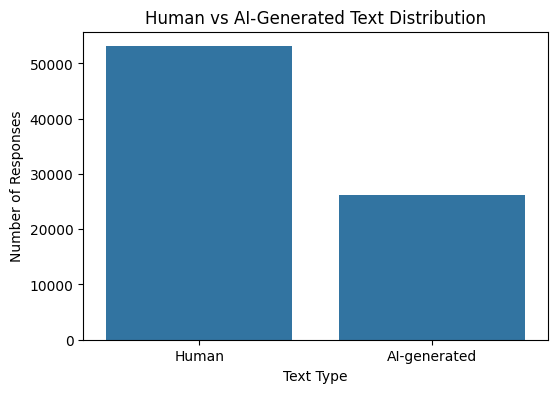

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

label_counts = ai_text_clean["label"].value_counts()

plt.figure(figsize=(6, 4))

sns.barplot(
    x=["Human", "AI-generated"],
    y=[
        label_counts.get(0, 0),
        label_counts.get(1, 0)
    ]
)

plt.title("Human vs AI-Generated Text Distribution")
plt.xlabel("Text Type")
plt.ylabel("Number of Responses")
plt.show()

In [ ]:
ai_text_clean["word_count"] = (
    ai_text_clean["text"]
    .str.split()
    .str.len()
)

ai_text_clean["text_length"] = (
    ai_text_clean["text"]
    .str.len()
)

ai_text_clean[["word_count", "text_length"]].describe()

,word_count,text_length
count,79331.000000,79331.000000
mean,147.761707,795.312816
std,140.564027,729.967053
min,1.000000,5.000000
25%,59.000000,300.000000
50%,121.000000,650.000000
75%,195.000000,1096.000000
max,7904.000000,36793.000000


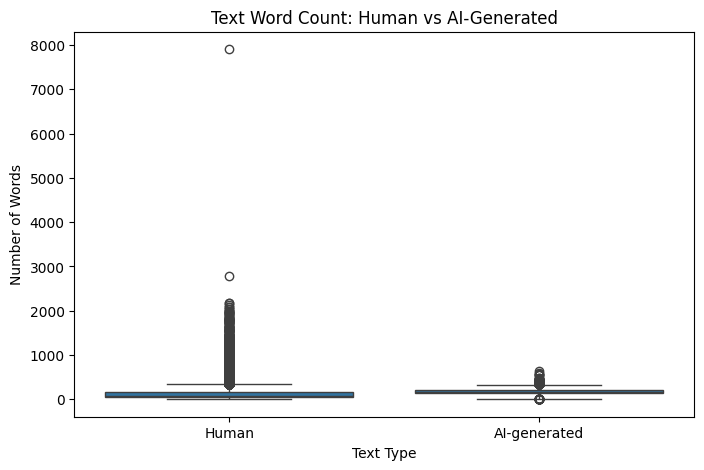

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=ai_text_clean,
    x="label",
    y="word_count"
)

plt.xticks([0, 1], ["Human", "AI-generated"])
plt.title("Text Word Count: Human vs AI-Generated")
plt.xlabel("Text Type")
plt.ylabel("Number of Words")

plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_ai = ai_text_clean["text"]
y_ai = ai_text_clean["label"]

X_ai_train, X_ai_test, y_ai_train, y_ai_test = train_test_split(
    X_ai,
    y_ai,
    test_size=0.20,
    random_state=42,
    stratify=y_ai
)

print("Training samples:", len(X_ai_train))
print("Testing samples:", len(X_ai_test))

Training samples: 63464
Testing samples: 15867


In [ ]:
import joblib
import os
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

# Load the already-trained model and TF-IDF
ai_text_model = joblib.load(
    os.path.join(models_dir, "ai_text_logistic_regression.pkl")
)

tfidf_ai = joblib.load(
    os.path.join(models_dir, "ai_text_tfidf.pkl")
)

print("AI Text model and TF-IDF loaded successfully!")

# Transform ONLY the original test data
X_ai_test_tfidf = tfidf_ai.transform(X_ai_test)

# Generate predictions
y_ai_pred = ai_text_model.predict(X_ai_test_tfidf)

# Calculate evaluation metrics
accuracy = accuracy_score(y_ai_test, y_ai_pred)

print("\n======================================")
print("     AI TEXT MODEL EVALUATION")
print("======================================")

print(f"\nAccuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_ai_test,
    y_ai_pred,
    target_names=["Human", "AI-generated"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_ai_test, y_ai_pred))

AI Text model and TF-IDF loaded successfully!

     AI TEXT MODEL EVALUATION

Accuracy: 98.05%

Classification Report:
              precision    recall  f1-score   support

       Human       0.99      0.99      0.99     10618
AI-generated       0.97      0.97      0.97      5249

    accuracy                           0.98     15867
   macro avg       0.98      0.98      0.98     15867
weighted avg       0.98      0.98      0.98     15867


Confusion Matrix:
[[10460   158]
 [  151  5098]]


In [ ]:
import os
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

results_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/results"
os.makedirs(results_dir, exist_ok=True)

# Save actual test predictions
ai_test_results = pd.DataFrame({
    "text": X_ai_test.values,
    "actual_label": y_ai_test.values,
    "predicted_label": y_ai_pred
})

ai_test_results.to_csv(
    os.path.join(results_dir, "ai_text_test_predictions.csv"),
    index=False
)

# Classification report
report = classification_report(
    y_ai_test,
    y_ai_pred,
    target_names=["Human", "AI-generated"]
)

# Confusion matrix
cm = confusion_matrix(y_ai_test, y_ai_pred)

# Save complete evaluation
with open(
    os.path.join(results_dir, "ai_text_evaluation_complete.txt"),
    "w"
) as f:

    f.write("AI-GENERATED TEXT DETECTION EVALUATION\n")
    f.write("======================================\n\n")

    f.write("Dataset: HC3\n")
    f.write("Original HC3 records: 24322\n")
    f.write("AI-text samples: 85431\n")
    f.write("Cleaned samples: 79331\n")
    f.write("Training samples: 63464\n")
    f.write("Testing samples: 15867\n\n")

    f.write("Model: Logistic Regression\n")
    f.write("TF-IDF features: 50000\n")
    f.write("N-gram range: (1, 2)\n")
    f.write("Random state: 42\n\n")

    f.write(f"Accuracy: {accuracy * 100:.2f}%\n\n")

    f.write("Classification Report:\n")
    f.write(report)

    f.write("\nConfusion Matrix:\n")
    f.write(str(cm))

print("======================================")
print("AI TEXT RESULTS SAVED SUCCESSFULLY!")
print("======================================")

print("\nFiles saved:")
print("✓ ai_text_test_predictions.csv")
print("✓ ai_text_evaluation_complete.txt")

AI TEXT RESULTS SAVED SUCCESSFULLY!

Files saved:
✓ ai_text_test_predictions.csv
✓ ai_text_evaluation_complete.txt


In [ ]:
print("Training label distribution:")
print(y_ai_train.value_counts())

print("\nTesting label distribution:")
print(y_ai_test.value_counts())

Training label distribution:
label
0    42468
1    20996
Name: count, dtype: int64

Testing label distribution:
label
0    10618
1     5249
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_ai = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [ ]:
X_ai_train_tfidf = tfidf_ai.fit_transform(X_ai_train)

X_ai_test_tfidf = tfidf_ai.transform(X_ai_test)

print("Training TF-IDF shape:", X_ai_train_tfidf.shape)
print("Testing TF-IDF shape:", X_ai_test_tfidf.shape)

Training TF-IDF shape: (63464, 50000)
Testing TF-IDF shape: (15867, 50000)


In [ ]:
from sklearn.linear_model import LogisticRegression

ai_text_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

ai_text_model.fit(
    X_ai_train_tfidf,
    y_ai_train
)

print("AI-text detection model trained successfully!")

AI-text detection model trained successfully!


In [ ]:
y_ai_pred = ai_text_model.predict(X_ai_test_tfidf)

print("Predictions completed!")
print(y_ai_pred[:20])

Predictions completed!
[1 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 1 0]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

ai_accuracy = accuracy_score(
    y_ai_test,
    y_ai_pred
)

print("AI-Text Detection Accuracy:", ai_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_ai_test,
        y_ai_pred,
        target_names=["Human", "AI-generated"]
    )
)

AI-Text Detection Accuracy: 0.9805256192096805

Classification Report:
              precision    recall  f1-score   support

       Human       0.99      0.99      0.99     10618
AI-generated       0.97      0.97      0.97      5249

    accuracy                           0.98     15867
   macro avg       0.98      0.98      0.98     15867
weighted avg       0.98      0.98      0.98     15867



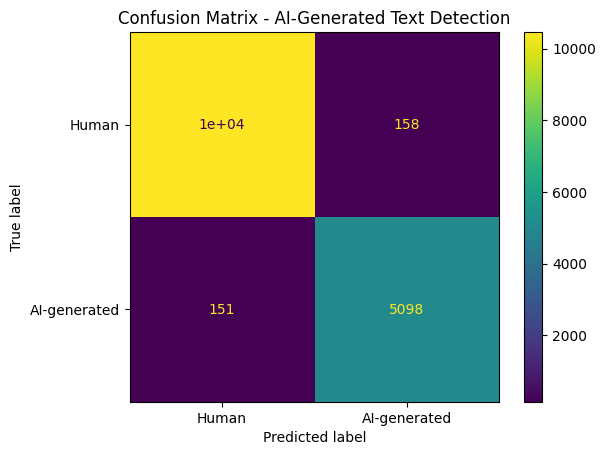

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_ai = confusion_matrix(y_ai_test, y_ai_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ai,
    display_labels=["Human", "AI-generated"]
)

disp.plot()

plt.title("Confusion Matrix - AI-Generated Text Detection")
plt.show()

In [ ]:
import joblib
import os

ai_model_path = os.path.join(
    project_path,
    "models",
    "ai_text_logistic_regression.pkl"
)

ai_tfidf_path = os.path.join(
    project_path,
    "models",
    "ai_text_tfidf.pkl"
)

joblib.dump(ai_text_model, ai_model_path)
joblib.dump(tfidf_ai, ai_tfidf_path)

print("AI-text model saved:", ai_model_path)
print("AI-text TF-IDF saved:", ai_tfidf_path)

AI-text model saved: /content/drive/MyDrive/AI_Unified_Content_Verification/models/ai_text_logistic_regression.pkl
AI-text TF-IDF saved: /content/drive/MyDrive/AI_Unified_Content_Verification/models/ai_text_tfidf.pkl


In [ ]:
import os

results_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/results"
os.makedirs(results_dir, exist_ok=True)

with open(
    os.path.join(results_dir, "ai_text_evaluation.txt"),
    "w"
) as f:
    f.write("AI-GENERATED TEXT DETECTION EVALUATION\n")
    f.write("======================================\n\n")
    f.write("Dataset: HC3\n")
    f.write("Original HC3 records: 24322\n")
    f.write("AI-text dataset samples: 85431\n")
    f.write("Cleaned dataset samples: 79331\n")
    f.write("Training samples: 63464\n")
    f.write("Testing samples: 15867\n\n")

    f.write("Feature Extraction: TF-IDF\n")
    f.write("Maximum features: 50000\n")
    f.write("N-gram range: (1, 2)\n")
    f.write("Minimum document frequency: 2\n")
    f.write("Maximum document frequency: 0.95\n")
    f.write("Sublinear TF: True\n\n")

    f.write("Model: Logistic Regression\n")
    f.write("Maximum iterations: 1000\n")
    f.write("Class weight: balanced\n")
    f.write("Random state: 42\n\n")

    f.write("Accuracy: 98.05%\n\n")

    f.write("Classification Report:\n")
    f.write("Human: Precision=0.99, Recall=0.99, F1=0.99, Support=10618\n")
    f.write("AI-generated: Precision=0.97, Recall=0.97, F1=0.97, Support=5249\n")
    f.write("Macro Average: Precision=0.98, Recall=0.98, F1=0.98\n")
    f.write("Weighted Average: Precision=0.98, Recall=0.98, F1=0.98\n")

print("AI Text evaluation saved successfully!")
print("Location:", os.path.join(results_dir, "ai_text_evaluation.txt"))

AI Text evaluation saved successfully!
Location: /content/drive/MyDrive/AI_Unified_Content_Verification/results/ai_text_evaluation.txt


In [ ]:
print("y_ai_test exists:", "y_ai_test" in globals())
print("y_ai_pred exists:", "y_ai_pred" in globals())

y_ai_test exists: False
y_ai_pred exists: False


Deepfake

In [ ]:
import tensorflow as tf

print("GPU available:", tf.config.list_physical_devices("GPU"))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!nvidia-smi

Fri Aug 14 13:16:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

project_path = "/content/drive/MyDrive/AI_Unified_Content_Verification"

print("Project folder exists:",
      os.path.exists(project_path))

Project folder exists: True


In [ ]:
deepfake_path = os.path.join(
    project_path,
    "datasets",
    "deepfake_images"
)

os.makedirs(deepfake_path, exist_ok=True)

print("Deepfake dataset folder:")
print(deepfake_path)

Deepfake dataset folder:
/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake_images


In [ ]:
!pip install -q kaggle

In [ ]:
import os

print("Kaggle installed successfully!")

Kaggle installed successfully!


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [ ]:
!kaggle datasets download -d xhlulu/140k-real-and-fake-faces \
    -p /content/deepfake_download

Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
140k-real-and-fake-faces.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
import os

zip_path = "/content/deepfake_download/140k-real-and-fake-faces.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    size_gb = os.path.getsize(zip_path) / (1024**3)
    print("ZIP size:", round(size_gb, 2), "GB")

ZIP exists: True
ZIP size: 3.75 GB


In [ ]:
!unzip -t "/content/deepfake_download/140k-real-and-fake-faces.zip" | tail -5

    testing: real_vs_fake/real-vs-fake/valid/real/69997.jpg   OK
    testing: test.csv                 OK
    testing: train.csv                OK
    testing: valid.csv                OK
No errors detected in compressed data of /content/deepfake_download/140k-real-and-fake-faces.zip.


In [ ]:
import zipfile
import os

zip_path = "/content/deepfake_download/140k-real-and-fake-faces.zip"

extract_path = "/content/deepfake_extracted"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
print(os.listdir(extract_path))


['test.csv', 'train.csv', 'valid.csv', 'real_vs_fake']


In [ ]:
import pandas as pd
import os

dataset_root = "/content/deepfake_extracted"

train_df = pd.read_csv(os.path.join(dataset_root, "train.csv"))
valid_df = pd.read_csv(os.path.join(dataset_root, "valid.csv"))
test_df = pd.read_csv(os.path.join(dataset_root, "test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", valid_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:")
print(train_df.columns)

print("\nFirst 5 training records:")
print(train_df.head())

Train shape: (100000, 6)
Validation shape: (20000, 6)
Test shape: (20000, 6)

Train columns:
Index(['Unnamed: 0', 'original_path', 'id', 'label', 'label_str', 'path'], dtype='object')

First 5 training records:
   Unnamed: 0                                      original_path     id  \
0           0  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  31355   
1           1  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  02884   
2           2  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  33988   
3           3  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  53875   
4           4  /kaggle/input/flickrfaceshq-dataset-nvidia-par...  24149   

   label label_str                  path  
0      1      real  train/real/31355.jpg  
1      1      real  train/real/02884.jpg  
2      1      real  train/real/33988.jpg  
3      1      real  train/real/53875.jpg  
4      1      real  train/real/24149.jpg  


In [ ]:
print("\nTrain label distribution:")
print(train_df.iloc[:, -1].value_counts())


Train label distribution:
path
train/fake/3KGORYX4I7.jpg    1
train/fake/V04IXCG0DK.jpg    1
train/fake/M5772EBE20.jpg    1
train/fake/FM15RG9PEP.jpg    1
train/fake/R2HNW5G90Z.jpg    1
                            ..
train/real/53875.jpg         1
train/real/24149.jpg         1
train/real/30627.jpg         1
train/real/62493.jpg         1
train/real/41925.jpg         1
Name: count, Length: 100000, dtype: int64


In [ ]:
print("Label values:")
print(train_df["label"].value_counts())

print("\nLabel names:")
print(train_df["label_str"].value_counts())

print("\nLabel mapping:")
print(
    train_df[["label", "label_str"]]
    .drop_duplicates()
    .sort_values("label")
)

Label values:
label
1    50000
0    50000
Name: count, dtype: int64

Label names:
label_str
real    50000
fake    50000
Name: count, dtype: int64

Label mapping:
       label label_str
50000      0      fake
0          1      real


In [ ]:
print("Train:")
print(train_df["label_str"].value_counts())

print("\nValidation:")
print(valid_df["label_str"].value_counts())

print("\nTest:")
print(test_df["label_str"].value_counts())

Train:
label_str
real    50000
fake    50000
Name: count, dtype: int64

Validation:
label_str
real    10000
fake    10000
Name: count, dtype: int64

Test:
label_str
real    10000
fake    10000
Name: count, dtype: int64


In [ ]:
import os

image_root = "/content/deepfake_extracted/real_vs_fake"

print("Contents of real_vs_fake:")
print(os.listdir(image_root))

print("\nTrain contents:")
print(os.listdir(os.path.join(image_root, "train"))[:10])

Contents of real_vs_fake:
['real-vs-fake']

Train contents:


FileNotFoundError: [Errno 2] No such file or directory: '/content/deepfake_extracted/real_vs_fake/train'

In [ ]:
image_root = "/content/deepfake_extracted/real_vs_fake/real-vs-fake"

print("Contents:")
print(os.listdir(image_root))

print("\nTrain contents:")
print(os.listdir(os.path.join(image_root, "train"))[:10])

Contents:
['train', 'test', 'valid']

Train contents:
['real', 'fake']


In [ ]:
import glob

real_images = glob.glob(
    os.path.join(image_root, "train", "real", "*.jpg")
)

fake_images = glob.glob(
    os.path.join(image_root, "train", "fake", "*.jpg")
)

print("Real images found:", len(real_images))
print("Fake images found:", len(fake_images))

print("\nExample real images:")
print(real_images[:3])

print("\nExample fake images:")
print(fake_images[:3])

Real images found: 50000
Fake images found: 50000

Example real images:
['/content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/69803.jpg', '/content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/01498.jpg', '/content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/12913.jpg']

Example fake images:
['/content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/EBHWFUKMNS.jpg', '/content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/F6G8BJTZK4.jpg', '/content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/EKTO8YQTVP.jpg']


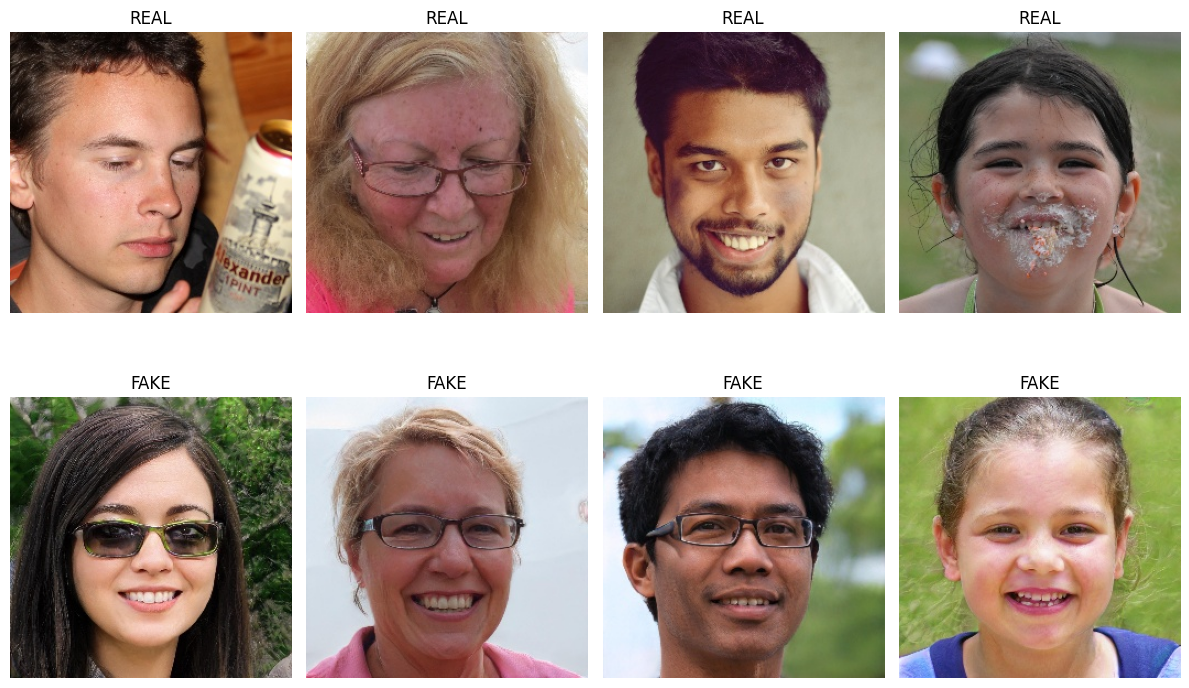

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

# Pick 4 real and 4 fake images
real_samples = random.sample(real_images, 4)
fake_samples = random.sample(fake_images, 4)

samples = [(path, "REAL") for path in real_samples] + \
          [(path, "FAKE") for path in fake_samples]

plt.figure(figsize=(12, 8))

for i, (path, label) in enumerate(samples):
    img = Image.open(path)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
img = Image.open(real_images[0])

print("Image size:", img.size)
print("Image mode:", img.mode)

Image size: (256, 256)
Image mode: RGB


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
import os

train_dir = os.path.join(image_root, "train")
valid_dir = os.path.join(image_root, "valid")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Class names:", train_ds.class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(valid_ds).numpy())

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Class names: ['fake', 'real']
Training batches: 3125
Validation batches: 625


In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

print("Data augmentation created successfully!")

Data augmentation created successfully!


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

# Load pretrained EfficientNetB0
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

# Build the model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

deepfake_model = models.Model(inputs, outputs)

deepfake_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
deepfake_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!


In [ ]:
history = deepfake_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=5
)

Epoch 1/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 319s 94ms/step - accuracy: 0.7449 - loss: 0.5115 - val_accuracy: 0.8074 - val_loss: 0.4322
Epoch 2/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 313s 92ms/step - accuracy: 0.7687 - loss: 0.4835 - val_accuracy: 0.8158 - val_loss: 0.4180
Epoch 3/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 329s 105ms/step - accuracy: 0.7709 - loss: 0.4779 - val_accuracy: 0.8177 - val_loss: 0.4123
Epoch 4/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 292s 94ms/step - accuracy: 0.7694 - loss: 0.4796 - val_accuracy: 0.8206 - val_loss: 0.4097
Epoch 5/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 293s 94ms/step - accuracy: 0.7706 - loss: 0.4773 - val_accuracy: 0.8207 - val_loss: 0.4103


In [ ]:
test_dir = os.path.join(image_root, "test")

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Test classes:", test_ds.class_names)
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 20000 files belonging to 2 classes.
Test classes: ['fake', 'real']
Test batches: 625


In [ ]:
test_loss, test_accuracy = deepfake_model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 75ms/step - accuracy: 0.8167 - loss: 0.4123
Test Loss: 0.41227245330810547
Test Accuracy: 0.8166999816894531


In [ ]:
print("Baseline Deepfake Detection Accuracy:", round(test_accuracy * 100, 2), "%")

Baseline Deepfake Detection Accuracy: 81.67 %


In [ ]:
# Unfreeze the EfficientNetB0 backbone
base_model.trainable = True

# Keep the earlier layers frozen and fine-tune only the later layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total EfficientNet layers:", len(base_model.layers))
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Total EfficientNet layers: 238
Trainable layers: 30


In [ ]:
deepfake_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully!")

Fine-tuning model compiled successfully!


In [ ]:
fine_tune_history = deepfake_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=3
)

Epoch 1/3
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 367s 112ms/step - accuracy: 0.7770 - loss: 0.4729 - val_accuracy: 0.8733 - val_loss: 0.3063
Epoch 2/3
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 378s 111ms/step - accuracy: 0.8378 - loss: 0.3628 - val_accuracy: 0.9043 - val_loss: 0.2460
Epoch 3/3
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 346s 111ms/step - accuracy: 0.8660 - loss: 0.3078 - val_accuracy: 0.9205 - val_loss: 0.2087


In [ ]:
fine_test_loss, fine_test_accuracy = deepfake_model.evaluate(test_ds)

print("Fine-tuned Test Loss:", fine_test_loss)
print("Fine-tuned Test Accuracy:", fine_test_accuracy)
print(
    "Fine-tuned Test Accuracy:",
    round(fine_test_accuracy * 100, 2),
    "%"
)

625/625 ━━━━━━━━━━━━━━━━━━━━ 48s 76ms/step - accuracy: 0.9187 - loss: 0.2100
Fine-tuned Test Loss: 0.21002131700515747
Fine-tuned Test Accuracy: 0.9186999797821045
Fine-tuned Test Accuracy: 91.87 %


625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 75ms/step
Classification Report:
              precision    recall  f1-score   support

        Fake       0.92      0.91      0.92     10000
        Real       0.91      0.92      0.92     10000

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000

Accuracy: 0.9187

Confusion Matrix:
[[9126  874]
 [ 752 9248]]


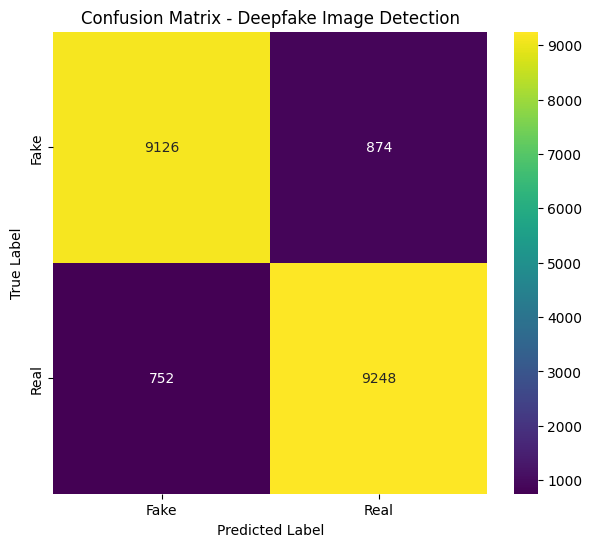

In [ ]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Get predictions
y_true = np.concatenate([
    y.numpy().ravel()
    for _, y in test_ds
])

y_prob = deepfake_model.predict(test_ds)
y_pred = (y_prob.ravel() >= 0.5).astype(int)

# Classification report
print("Classification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Fake", "Real"]
    )
)

# Accuracy
print("Accuracy:", accuracy_score(y_true, y_pred))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="viridis",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Deepfake Image Detection")
plt.show()

In [ ]:
model_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras"

deepfake_model.save(model_path)

print("Final deepfake model saved successfully!")
print(model_path)

Final deepfake model saved successfully!
/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

def predict_deepfake(img_path):
    # Load and resize image
    img = image.load_img(
        img_path,
        target_size=(224, 224)
    )

    # Convert image to array
    img_array = image.img_to_array(img)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    probability = deepfake_model.predict(img_array, verbose=0)[0][0]

    # TensorFlow class mapping:
    # 0 = fake
    # 1 = real
    if probability >= 0.5:
        prediction = "REAL"
        confidence = probability * 100
    else:
        prediction = "AI-GENERATED / FAKE"
        confidence = (1 - probability) * 100

    print("Prediction:", prediction)
    print("Confidence:", round(confidence, 2), "%")

    return prediction, confidence

In [ ]:
real_test_image = real_images[0]

print("Testing:", real_test_image)

predict_deepfake(real_test_image)

Testing: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/69803.jpg
Prediction: REAL
Confidence: 99.56 %


('REAL', np.float32(99.56252))

In [ ]:
fake_test_image = fake_images[0]

print("Testing:", fake_test_image)

predict_deepfake(fake_test_image)

Testing: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/EBHWFUKMNS.jpg
Prediction: REAL
Confidence: 53.78 %


('REAL', np.float32(53.783787))

In [ ]:
print("Testing 10 known FAKE images:\n")

for i in range(10):
    print(f"--- Fake image {i+1} ---")
    print(f"File: {fake_images[i]}")
    predict_deepfake(fake_images[i])
    print()

Testing 10 known FAKE images:

--- Fake image 1 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/EBHWFUKMNS.jpg
Prediction: REAL
Confidence: 53.78 %

--- Fake image 2 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/F6G8BJTZK4.jpg
Prediction: AI-GENERATED / FAKE
Confidence: 88.28 %

--- Fake image 3 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/EKTO8YQTVP.jpg
Prediction: AI-GENERATED / FAKE
Confidence: 99.18 %

--- Fake image 4 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/K3GM266Y89.jpg
Prediction: AI-GENERATED / FAKE
Confidence: 68.58 %

--- Fake image 5 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/72ACGV6XP1.jpg
Prediction: AI-GENERATED / FAKE
Confidence: 85.24 %

--- Fake image 6 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/fake/IBPWXCSZ48.jpg
Prediction: AI-GENERATED / FAKE
Confidence: 82.05 %

--- Fake image 7 ---
Fil

In [ ]:
print("Testing 10 known REAL images:\n")

for i in range(10):
    print(f"--- Real image {i+1} ---")
    print(f"File: {real_images[i]}")
    predict_deepfake(real_images[i])
    print()

Testing 10 known REAL images:

--- Real image 1 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/69803.jpg
Prediction: REAL
Confidence: 99.56 %

--- Real image 2 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/01498.jpg
Prediction: REAL
Confidence: 96.09 %

--- Real image 3 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/12913.jpg
Prediction: AI-GENERATED / FAKE
Confidence: 54.22 %

--- Real image 4 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/01922.jpg
Prediction: REAL
Confidence: 93.23 %

--- Real image 5 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/57363.jpg
Prediction: REAL
Confidence: 99.67 %

--- Real image 6 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/35866.jpg
Prediction: REAL
Confidence: 73.67 %

--- Real image 7 ---
File: /content/deepfake_extracted/real_vs_fake/real-vs-fake/train/real/02531.jpg
Prediction: 

In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake(filename)

Saving Screenshot 2026-08-14 204710.png to Screenshot 2026-08-14 204710.png
Testing image: Screenshot 2026-08-14 204710.png
Prediction: REAL
Confidence: 96.93 %


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith(('.h5', '.keras')):
            print(os.path.join(root, file))

/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras


In [ ]:
from tensorflow.keras.models import load_model

model_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras"

model = load_model(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_image(img_path):
    # Load and resize image
    img = image.load_img(img_path, target_size=(224, 224))

    # Convert image to array
    img_array = image.img_to_array(img)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Normalize pixel values
    img_array = img_array / 255.0

    # Make prediction
    prediction = model.predict(img_array, verbose=0)[0][0]

    # Display result
    if prediction >= 0.5:
        result = "Fake"
        confidence = prediction * 100
    else:
        result = "Real"
        confidence = (1 - prediction) * 100

    print("Prediction:", result)
    print("Confidence: {:.2f}%".format(confidence))

    return result, confidence

In [ ]:
img_path = "/content/women.jpg"

predict_image(img_path)

Prediction: Real
Confidence: 67.95%


('Real', np.float32(67.948326))

In [ ]:
img_path = "/content/beauty-woman-face-portrait-beautiful-spa-model-girl-with-perfect-fresh-clean-skin-generated-by-ai_911060-3271.avif"

predict_image(img_path)

Prediction: Real
Confidence: 67.64%


('Real', np.float32(67.639565))

In [ ]:
img_path = "/content/download.webp"
predict_image(img_path)

Prediction: Real
Confidence: 67.65%


('Real', np.float32(67.652435))

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

def check_prediction(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    prediction = model.predict(img_array, verbose=0)[0][0]

    print("Raw model output:", prediction)

check_prediction("/content/women.jpg")

Raw model output: 0.32051677


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/AI_Unified_Content_Verification"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = "  " * level
    print(indent + os.path.basename(root) + "/")

AI_Unified_Content_Verification/
  datasets/
    fake_news/
    ai_text/
    deepfake_images/
  models/
  results/
  reports/


In [ ]:
import os

deepfake_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake_images"

print("Contents:")
for item in os.listdir(deepfake_path):
    print(item)

Contents:


In [ ]:
import os

project_path = "/content/drive/MyDrive/AI_Unified_Content_Verification"

for root, dirs, files in os.walk(project_path):
    for file in files:
        print(os.path.join(root, file))

/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/fake_news/WELFake_Dataset.csv
/content/drive/MyDrive/AI_Unified_Content_Verification/models/fake_news_logistic_regression.pkl
/content/drive/MyDrive/AI_Unified_Content_Verification/models/fake_news_tfidf.pkl
/content/drive/MyDrive/AI_Unified_Content_Verification/models/ai_text_logistic_regression.pkl
/content/drive/MyDrive/AI_Unified_Content_Verification/models/ai_text_tfidf.pkl
/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras


In [ ]:
print(model.layers[-1].activation)

<function sigmoid at 0x7f37a1344b80>


In [ ]:
print("Loss:", model.loss)
print("Metrics:", model.metrics_names)

Loss: binary_crossentropy
Metrics: ['loss', 'compile_metrics']


In [ ]:
def predict_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0

    # Model output = probability of REAL
    real_probability = model.predict(img_array, verbose=0)[0][0]

    fake_probability = 1 - real_probability

    if real_probability >= 0.5:
        result = "Real"
        confidence = real_probability * 100
    else:
        result = "Fake / AI-generated"
        confidence = fake_probability * 100

    print("Prediction:", result)
    print("Confidence: {:.2f}%".format(confidence))

    return result, confidence

In [ ]:
predict_image("/content/women.jpg")

Prediction: Fake / AI-generated
Confidence: 67.95%


('Fake / AI-generated', np.float32(67.948326))

In [ ]:
predict_image("/content/beauty-woman-face-portrait-beautiful-spa-model-girl-with-perfect-fresh-clean-skin-generated-by-ai_911060-3271.avif")

Prediction: Fake / AI-generated
Confidence: 67.64%


('Fake / AI-generated', np.float32(67.639565))

In [ ]:
predict_image("/content/download.webp")

Prediction: Fake / AI-generated
Confidence: 67.65%


('Fake / AI-generated', np.float32(67.652435))

In [ ]:
predict_image("/content/real.jpg")

Prediction: Fake / AI-generated
Confidence: 67.81%


('Fake / AI-generated', np.float32(67.8146))

In [ ]:
def predict_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Do NOT divide by 255
    real_probability = model.predict(img_array, verbose=0)[0][0]
    fake_probability = 1 - real_probability

    if real_probability >= 0.5:
        result = "Real"
        confidence = real_probability * 100
    else:
        result = "Fake / AI-generated"
        confidence = fake_probability * 100

    print("Prediction:", result)
    print("Confidence: {:.2f}%".format(confidence))

    return result, confidence

In [ ]:
predict_image("/content/real.jpg")

Prediction: Real
Confidence: 83.20%


('Real', np.float32(83.20242))

In [ ]:
predict_image("/content/download.webp")

Prediction: Real
Confidence: 87.68%


('Real', np.float32(87.677895))

In [ ]:
for i, layer in enumerate(model.layers[:10]):
    print(i, layer.name, type(layer).__name__)

0 input_layer_1 InputLayer
1 data_augmentation Sequential
2 efficientnetb0 Functional
3 global_average_pooling2d GlobalAveragePooling2D
4 dropout Dropout
5 dense Dense


In [ ]:
print("EfficientNet sublayers:")
for i, layer in enumerate(model.layers[2].layers[:10]):
    print(i, layer.name, type(layer).__name__)

EfficientNet sublayers:
0 input_layer InputLayer
1 rescaling Rescaling
2 normalization Normalization
3 rescaling_1 Rescaling
4 stem_conv_pad ZeroPadding2D
5 stem_conv Conv2D
6 stem_bn BatchNormalization
7 stem_activation Activation
8 block1a_dwconv DepthwiseConv2D
9 block1a_bn BatchNormalization


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_image(img_path):

    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # EfficientNetB0 already performs its own preprocessing
    real_probability = float(model.predict(img_array, verbose=0)[0][0])

    fake_probability = 1 - real_probability

    if real_probability >= 0.5:
        result = "Real"
        confidence = real_probability * 100
    else:
        result = "Fake / AI-generated"
        confidence = fake_probability * 100

    print("Prediction:", result)
    print("Confidence: {:.2f}%".format(confidence))

    return result, confidence

In [ ]:
from tensorflow.keras.models import load_model

model_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras"

model = load_model(model_path)

print("Model loaded successfully!")

Model loaded successfully!


Saving real 7.jpg to real 7.jpg

Analyzing: real 7.jpg


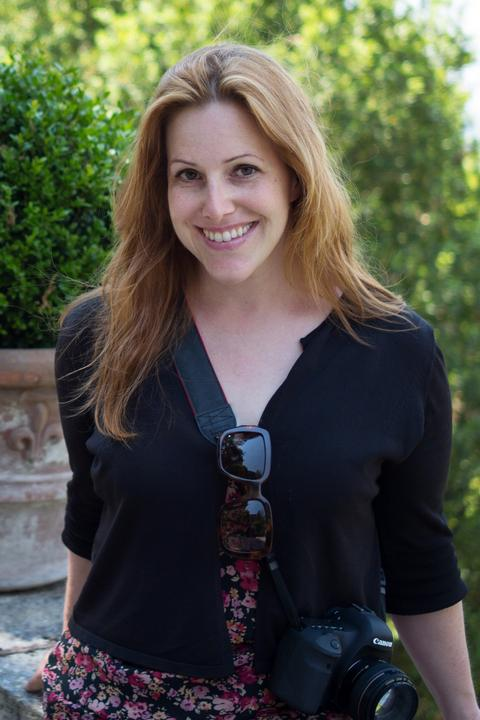

Prediction: Real
Confidence: 99.89%


In [ ]:
from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()

for filename in uploaded.keys():
    print("\nAnalyzing:", filename)

    display(Image.open(filename))

    result, confidence = predict_image(filename)

Saving fake4.jpg to fake4.jpg

Analyzing: fake4.jpg


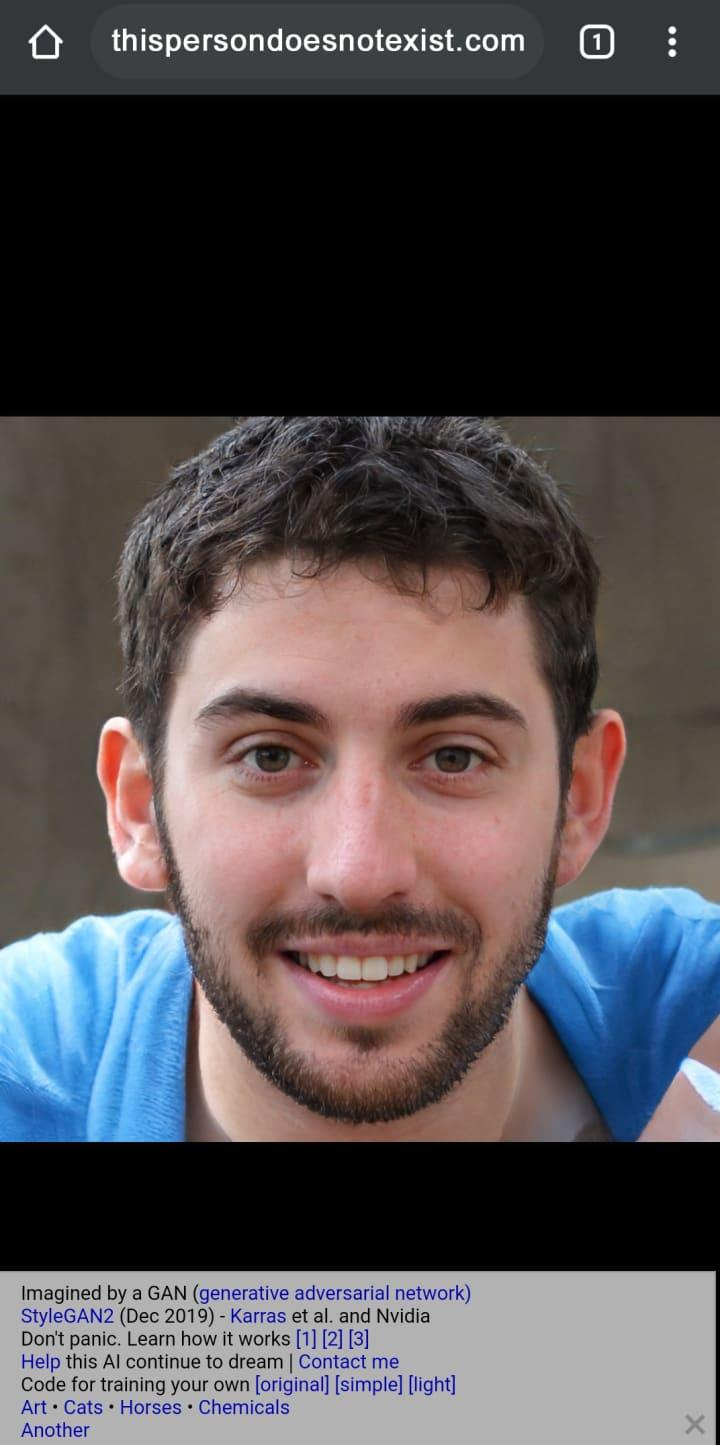

Prediction: Real
Confidence: 98.95%


In [ ]:
from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()

for filename in uploaded.keys():
    print("\nAnalyzing:", filename)

    display(Image.open(filename))

    result, confidence = predict_image(filename)

In [ ]:
import os

fake_test_path = "/content/original_test/fake/00276TOPP4.jpg"

if os.path.exists(fake_test_path):
    print("Original fake test image found!")
    predict_image(fake_test_path)
else:
    print("Original fake test image is not available.")

Original fake test image is not available.


In [ ]:
print("Optimizer:", model.optimizer)
print("Loss:", model.loss)
print("Input:", model.input_shape)
print("Output:", model.output_shape)

Optimizer: <keras.src.optimizers.adam.Adam object at 0x79c4c8d09e50>
Loss: binary_crossentropy
Input: (None, 224, 224, 3)
Output: (None, 1)


In [ ]:
print("\nModel summary:")
model.summary()


Model summary:


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,045,736 (26.88 MB)

 Trainable params: 1,497,441 (5.71 MB)

 Non-trainable params: 2,553,411 (9.74 MB)

 Optimizer params: 2,994,884 (11.42 MB)

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

project_path = "/content/drive/MyDrive/AI_Unified_Content_Verification"

print("Project folder exists:", os.path.exists(project_path))
print("\nModel files:")

models_path = os.path.join(project_path, "models")

for file in os.listdir(models_path):
    print("-", file)

Project folder exists: True

Model files:
- fake_news_logistic_regression.pkl
- fake_news_tfidf.pkl
- ai_text_logistic_regression.pkl
- ai_text_tfidf.pkl
- deepfake_efficientnet_final.keras


In [ ]:
import joblib
import os

fake_news_model_path = os.path.join(
    models_path,
    "fake_news_logistic_regression.pkl"
)

fake_news_tfidf_path = os.path.join(
    models_path,
    "fake_news_tfidf.pkl"
)

fake_news_model = joblib.load(fake_news_model_path)
fake_news_tfidf = joblib.load(fake_news_tfidf_path)

print("Fake News model loaded successfully!")
print("Fake News TF-IDF loaded successfully!")

Fake News model loaded successfully!
Fake News TF-IDF loaded successfully!


In [ ]:
print("Model type:", type(fake_news_model))
print("TF-IDF type:", type(fake_news_tfidf))

Model type: <class 'sklearn.linear_model._logistic.LogisticRegression'>
TF-IDF type: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>


In [ ]:
def predict_fake_news(title, text):
    # Combine title and article text
    combined_text = title + " " + text

    # Convert text using the same TF-IDF vectorizer
    text_tfidf = fake_news_tfidf.transform([combined_text])

    # Predict
    prediction = fake_news_model.predict(text_tfidf)[0]

    # Get confidence
    probabilities = fake_news_model.predict_proba(text_tfidf)[0]
    confidence = max(probabilities) * 100

    # WELFake mapping used in our project:
    # 0 = Fake
    # 1 = Real
    if prediction == 0:
        result = "FAKE NEWS"
    else:
        result = "REAL NEWS"

    print("Prediction:", result)
    print("Confidence:", round(confidence, 2), "%")

    return result, confidence

In [ ]:
test_title = "Example News Article"
test_text = """
This is a test article used to verify that our fake news
detection model and TF-IDF vectorizer are working correctly.
"""

predict_fake_news(test_title, test_text)

Prediction: REAL NEWS
Confidence: 96.55 %


('REAL NEWS', np.float64(96.54930214802518))

In [ ]:
ai_text_model_path = os.path.join(
    models_path,
    "ai_text_logistic_regression.pkl"
)

ai_text_tfidf_path = os.path.join(
    models_path,
    "ai_text_tfidf.pkl"
)

ai_text_model = joblib.load(ai_text_model_path)
ai_text_tfidf = joblib.load(ai_text_tfidf_path)

print("AI Text model loaded successfully!")
print("AI Text TF-IDF loaded successfully!")

AI Text model loaded successfully!
AI Text TF-IDF loaded successfully!


In [ ]:
print("Model type:", type(ai_text_model))
print("TF-IDF type:", type(ai_text_tfidf))

Model type: <class 'sklearn.linear_model._logistic.LogisticRegression'>
TF-IDF type: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>


In [ ]:
def predict_ai_text(text):
    # Convert text using the same TF-IDF vectorizer
    text_tfidf = ai_text_tfidf.transform([text])

    # Predict
    prediction = ai_text_model.predict(text_tfidf)[0]

    # Get confidence
    probabilities = ai_text_model.predict_proba(text_tfidf)[0]
    confidence = max(probabilities) * 100

    # HC3 mapping used in our project:
    # 0 = Human
    # 1 = AI-generated
    if prediction == 0:
        result = "HUMAN-WRITTEN"
    else:
        result = "AI-GENERATED"

    print("Prediction:", result)
    print("Confidence:", round(confidence, 2), "%")

    return result, confidence

In [ ]:
test_ai_text = """
Artificial intelligence is transforming many areas of modern technology.
Machine learning systems can analyze large amounts of data and identify
patterns that help people make better decisions.
"""

predict_ai_text(test_ai_text)

Prediction: HUMAN-WRITTEN
Confidence: 75.29 %


('HUMAN-WRITTEN', np.float64(75.29291630137686))

In [ ]:
test_ai_text = """
Machine learning is a subset of artifiical datascience. it is used to train models
"""

predict_ai_text(test_ai_text)

Prediction: HUMAN-WRITTEN
Confidence: 76.46 %


('HUMAN-WRITTEN', np.float64(76.45920867396651))

In [ ]:
import tensorflow as tf

deepfake_model_path = os.path.join(
    models_path,
    "deepfake_efficientnet_final.keras"
)

deepfake_model = tf.keras.models.load_model(deepfake_model_path)

print("Deepfake model loaded successfully!")
print("Input shape:", deepfake_model.input_shape)
print("Output shape:", deepfake_model.output_shape)

Deepfake model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

def predict_deepfake_unified(img_path):
    # Load image
    img = image.load_img(
        img_path,
        target_size=(224, 224)
    )

    # Convert to array
    img_array = image.img_to_array(img)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    probability = deepfake_model.predict(
        img_array,
        verbose=0
    )[0][0]

    # Model mapping:
    # 0 = Fake
    # 1 = Real
    if probability >= 0.5:
        result = "REAL"
        confidence = probability * 100
    else:
        result = "AI-GENERATED / FAKE"
        confidence = (1 - probability) * 100

    print("Prediction:", result)
    print("Confidence:", round(confidence, 2), "%")

    return result, confidence

In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving real 7.jpg to real 7.jpg
Testing image: real 7.jpg
Prediction: REAL
Confidence: 99.89 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving test.png to test.png
Testing image: test.png
Prediction: REAL
Confidence: 98.58 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving test real 1.jpg to test real 1.jpg
Testing image: test real 1.jpg
Prediction: REAL
Confidence: 99.94 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving test real 2.jpg to test real 2.jpg
Testing image: test real 2.jpg
Prediction: REAL
Confidence: 100.0 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving test real 3.jpg to test real 3.jpg
Testing image: test real 3.jpg
Prediction: AI-GENERATED / FAKE
Confidence: 72.57 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving test real 4.jpg to test real 4.jpg
Testing image: test real 4.jpg
Prediction: REAL
Confidence: 99.97 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving test real 5.jpg to test real 5.jpg
Testing image: test real 5.jpg
Prediction: REAL
Confidence: 99.98 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving Screenshot 2026-08-18 183429.png to Screenshot 2026-08-18 183429.png
Testing image: Screenshot 2026-08-18 183429.png
Prediction: REAL
Confidence: 92.01 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving Screenshot 2026-08-18 183437.png to Screenshot 2026-08-18 183437.png
Testing image: Screenshot 2026-08-18 183437.png
Prediction: REAL
Confidence: 99.09 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving Screenshot 2026-08-18 183444.png to Screenshot 2026-08-18 183444.png
Testing image: Screenshot 2026-08-18 183444.png
Prediction: REAL
Confidence: 74.55 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving Screenshot 2026-08-18 183451.png to Screenshot 2026-08-18 183451.png
Testing image: Screenshot 2026-08-18 183451.png
Prediction: REAL
Confidence: 97.64 %


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    print("Testing image:", filename)
    predict_deepfake_unified(filename)

Saving Screenshot 2026-08-18 183459.png to Screenshot 2026-08-18 183459.png
Testing image: Screenshot 2026-08-18 183459.png
Prediction: REAL
Confidence: 98.69 %


In [ ]:
print("Current model layers:")
for i, layer in enumerate(deepfake_model.layers):
    print(i, layer.name, layer.__class__.__name__)

Current model layers:
0 input_layer_1 InputLayer
1 data_augmentation Sequential
2 efficientnetb0 Functional
3 global_average_pooling2d GlobalAveragePooling2D
4 dropout Dropout
5 dense Dense


In [ ]:
print("\nData augmentation configuration:")
print(deepfake_model.get_layer("data_augmentation").get_config())


Data augmentation configuration:
{'name': 'data_augmentation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_layer_2', 'optional': False}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'seed': None, 'mode': 'horizontal', 'data_format': 'channels_last'}, 'registered_name': None, 'build_config': {'input_shape': [None, 224, 224, 3]}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name':

In [ ]:
import os

dataset_path = "/content/deepfake_extracted/real_vs_fake/real-vs-fake"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Train exists:", os.path.exists(os.path.join(dataset_path, "train")))
    print("Validation exists:", os.path.exists(os.path.join(dataset_path, "valid")))
    print("Test exists:", os.path.exists(os.path.join(dataset_path, "test")))

Dataset exists: False


In [ ]:
import os

print("Deepfake download folder exists:",
      os.path.exists("/content/deepfake_download"))

if os.path.exists("/content/deepfake_download"):
    print("\nFiles:")
    print(os.listdir("/content/deepfake_download"))

Deepfake download folder exists: False


In [ ]:
import os

print("Kaggle credentials exist:",
      os.path.exists("/root/.kaggle/kaggle.json"))

Kaggle credentials exist: False


***Kaggle***



In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.move(
    "kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [ ]:
print(
    "Kaggle credentials exist:",
    os.path.exists("/root/.kaggle/kaggle.json")
)

Kaggle credentials exist: True


In [ ]:
import os

deepfake_drive = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake"

os.makedirs(deepfake_drive, exist_ok=True)

print("Dataset folder:", deepfake_drive)

Dataset folder: /content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake


In [ ]:
!kaggle datasets download -d xhlulu/140k-real-and-fake-faces \
    -p "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake"

Dataset URL: https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces
License(s): other
100% 3.75G/3.75G [03:00<00:00, 22.3MB/s]



In [ ]:
import os

print(os.listdir(deepfake_drive))

['140k-real-and-fake-faces.zip']


In [ ]:
import os

extract_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/extracted"

os.makedirs(extract_path, exist_ok=True)

print("Extracting dataset...")

Extracting dataset...


In [ ]:
!unzip -q "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip" \
    -d "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/extracted"

print("Extraction completed!")

Extraction completed!


In [ ]:
import os

extract_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/extracted"

print("Extracted folder exists:", os.path.exists(extract_path))
print("Contents:", os.listdir(extract_path))

Extracted folder exists: True
Contents: ['real_vs_fake']


In [ ]:
deepfake_root = os.path.join(
    extract_path,
    "real_vs_fake",
    "real-vs-fake"
)

print("Deepfake root:", deepfake_root)
print("Contents:", os.listdir(deepfake_root))

Deepfake root: /content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/extracted/real_vs_fake/real-vs-fake
Contents: ['test', 'train', 'valid']


In [ ]:
!unzip -l "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip" | grep "valid/" | head

    21816  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/00483R5CC4.jpg
    32513  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/007SMMOPYB.jpg
    26978  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/008Y48BIX8.jpg
    31820  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/00BYVMEI3I.jpg
    31993  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/00GN2JWV43.jpg
    28742  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/00JMWC4S8R.jpg
    30322  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/00V8VPXL3V.jpg
    23257  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/00W5NPIX4S.jpg
    27609  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/012N2T4FKG.jpg
    29917  2020-02-10 17:34   real_vs_fake/real-vs-fake/valid/fake/013O4R3GO3.jpg


In [ ]:
import os

for root, dirs, files in os.walk(extract_path):
    if os.path.basename(root) == "valid":
        print("Found valid folder:")
        print(root)

Found valid folder:
/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/extracted/real_vs_fake/real-vs-fake/valid


In [ ]:
train_dir = os.path.join(deepfake_root, "train")
valid_dir = os.path.join(deepfake_root, "valid")
test_dir = os.path.join(deepfake_root, "test")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

print("Datasets recreated successfully!")
print("Classes:", train_ds.class_names)

Found 23340 files belonging to 1 classes.


ValueError: When passing `label_mode="binary"`, there must be exactly 2 class_names. Received: class_names=['fake']

In [ ]:
import os

print("Train folder:")
print(os.listdir(train_dir))

print("\nFake folder exists:",
      os.path.exists(os.path.join(train_dir, "fake")))

print("Real folder exists:",
      os.path.exists(os.path.join(train_dir, "real")))

if os.path.exists(os.path.join(train_dir, "fake")):
    print("Fake images:",
          len(os.listdir(os.path.join(train_dir, "fake"))))

if os.path.exists(os.path.join(train_dir, "real")):
    print("Real images:",
          len(os.listdir(os.path.join(train_dir, "real"))))

Train folder:
['fake']

Fake folder exists: True
Real folder exists: False
Fake images: 23340


In [ ]:
import os

local_dataset = "/content/deepfake_local"
os.makedirs(local_dataset, exist_ok=True)

print("Local dataset folder ready:", local_dataset)

Local dataset folder ready: /content/deepfake_local


In [ ]:
!unzip -q \
"/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip" \
-d "/content/deepfake_local"

In [ ]:
print(os.listdir(local_dataset))

['test.csv', 'real_vs_fake', 'train.csv', 'valid.csv']


In [ ]:
local_root = os.path.join(
    local_dataset,
    "real_vs_fake",
    "real-vs-fake"
)

print("Correct local root:")
print(local_root)

print("\nContents:")
print(os.listdir(local_root))

Correct local root:
/content/deepfake_local/real_vs_fake/real-vs-fake

Contents:
['valid', 'train', 'test']


In [ ]:
print("Train:", os.listdir(os.path.join(local_root, "train")))
print("Validation:", os.listdir(os.path.join(local_root, "valid")))
print("Test:", os.listdir(os.path.join(local_root, "test")))

Train: ['fake', 'real']
Validation: ['fake', 'real']
Test: ['fake', 'real']


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = os.path.join(local_root, "train")
valid_dir = os.path.join(local_root, "valid")
test_dir = os.path.join(local_root, "test")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Datasets created successfully!")
print("Classes:", train_ds.class_names)

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Datasets created successfully!
Classes: ['fake', 'real']


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

IMG_SIZE = (224, 224)

# Improved data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15)
], name="data_augmentation")

# Pretrained EfficientNetB0
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze backbone for initial training
base_model.trainable = False

# Build improved model
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

improved_model = models.Model(inputs, outputs)

# Compile
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Improved model created successfully!")
print("Total parameters:", improved_model.count_params())

Improved model created successfully!
Total parameters: 4050852


In [ ]:
history_improved = improved_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=5
)

Epoch 1/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 323s 99ms/step - accuracy: 0.6781 - loss: 0.5960 - val_accuracy: 0.7556 - val_loss: 0.5195
Epoch 2/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 350s 112ms/step - accuracy: 0.7304 - loss: 0.5385 - val_accuracy: 0.7757 - val_loss: 0.4894
Epoch 3/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 316s 101ms/step - accuracy: 0.7411 - loss: 0.5239 - val_accuracy: 0.7839 - val_loss: 0.4749
Epoch 4/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 325s 104ms/step - accuracy: 0.7458 - loss: 0.5139 - val_accuracy: 0.7897 - val_loss: 0.4652
Epoch 5/5
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 314s 100ms/step - accuracy: 0.7518 - loss: 0.5069 - val_accuracy: 0.7932 - val_loss: 0.4586


In [ ]:
# Unfreeze EfficientNetB0
base_model.trainable = True

# Freeze earlier layers
for layer in base_model.layers[:-60]:
    layer.trainable = False

print("Total EfficientNet layers:", len(base_model.layers))
print(
    "Trainable EfficientNet layers:",
    sum(layer.trainable for layer in base_model.layers)
)

# Recompile with a very small learning rate
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully!")


Total EfficientNet layers: 238
Trainable EfficientNet layers: 60
Fine-tuning model compiled successfully!


In [ ]:
fine_tune_history = improved_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=3
)

Epoch 1/3
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 480s 146ms/step - accuracy: 0.7808 - loss: 0.4580 - val_accuracy: 0.8758 - val_loss: 0.2944
Epoch 2/3
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 452s 145ms/step - accuracy: 0.8630 - loss: 0.3176 - val_accuracy: 0.9175 - val_loss: 0.2078
Epoch 3/3
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 417s 133ms/step - accuracy: 0.8910 - loss: 0.2590 - val_accuracy: 0.9359 - val_loss: 0.1633


In [ ]:
improved_test_loss, improved_test_accuracy = improved_model.evaluate(
    test_ds
)

print("Improved Test Loss:", improved_test_loss)
print("Improved Test Accuracy:", improved_test_accuracy)
print(
    "Improved Test Accuracy:",
    round(improved_test_accuracy * 100, 2),
    "%"
)

625/625 ━━━━━━━━━━━━━━━━━━━━ 51s 81ms/step - accuracy: 0.9366 - loss: 0.1637
Improved Test Loss: 0.16367225348949432
Improved Test Accuracy: 0.9366000294685364
Improved Test Accuracy: 93.66 %


In [ ]:
from PIL import Image
import numpy as np

def predict_deepfake_unified(image_path):
    # Load image
    img = Image.open(image_path).convert("RGB")

    # Resize to model input size
    img = img.resize((224, 224))

    # Convert to array
    img_array = np.array(img, dtype=np.float32)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict using the IMPROVED model
    probability = improved_model.predict(img_array, verbose=0)[0][0]

    # Dataset mapping:
    # 0 = fake
    # 1 = real
    if probability >= 0.5:
        prediction = "REAL"
        confidence = probability * 100
    else:
        prediction = "AI-GENERATED / FAKE"
        confidence = (1 - probability) * 100

    print("Prediction:", prediction)
    print("Confidence:", f"{confidence:.2f} %")

    return prediction, confidence

In [ ]:
def check_deepfake_probability(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))

    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    probability = improved_model.predict(img_array, verbose=0)[0][0]

    print("Raw model output:", probability)
    print("If 0 = FAKE and 1 = REAL:")

    if probability >= 0.5:
        print("Prediction: REAL")
    else:
        print("Prediction: AI-GENERATED / FAKE")

In [ ]:
check_deepfake_probability("/content/teast fake1 (1).png")

Raw model output: 0.9887706
If 0 = FAKE and 1 = REAL:
Prediction: REAL


real

In [ ]:
predict_deepfake_unified("test real 2.jpg")

Prediction: REAL
Confidence: 99.98 %


('REAL', np.float32(99.97696))

fake/ai

In [ ]:
from PIL import Image
import numpy as np

def check_raw_prediction(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))

    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    probability = improved_model.predict(img_array, verbose=0)[0][0]

    print("Raw model output:", float(probability))
    print("Interpretation:")

    if probability >= 0.5:
        print("REAL")
    else:
        print("AI-GENERATED / FAKE")

check_raw_prediction("test real 2.jpg")

Raw model output: 0.9997696280479431
Interpretation:
REAL


In [ ]:
print("Class names:", train_ds.class_names)

Class names: ['fake', 'real']


In [ ]:
# Evaluate the improved model on the test dataset

test_loss, test_accuracy = improved_model.evaluate(test_ds, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

625/625 ━━━━━━━━━━━━━━━━━━━━ 51s 81ms/step - accuracy: 0.9366 - loss: 0.1637
Test Loss: 0.16367225348949432
Test Accuracy: 0.9366000294685364


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Get predictions from the test dataset
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = improved_model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_pred.extend((predictions.flatten() >= 0.5).astype(int))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["FAKE", "REAL"]
    )
)

Confusion Matrix:
[[9444  556]
 [ 712 9288]]

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.93      0.94      0.94     10000
        REAL       0.94      0.93      0.94     10000

    accuracy                           0.94     20000
   macro avg       0.94      0.94      0.94     20000
weighted avg       0.94      0.94      0.94     20000



In [ ]:
improved_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,397,544 (35.85 MB)

 Trainable params: 2,673,345 (10.20 MB)

 Non-trainable params: 1,377,507 (5.25 MB)

 Optimizer params: 5,346,692 (20.40 MB)

In [ ]:
img = Image.open("/content/teast fake1 (1).png").convert("RGB")
img = img.resize((224, 224))

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

probability = improved_model.predict(img_array, verbose=0)[0][0]

print("Raw model output:", probability)
print("Real probability:", probability * 100)
print("Fake probability:", (1 - probability) * 100)

Raw model output: 0.9887706
Real probability: 98.87706
Fake probability: 1.1229396


In [ ]:
# Test predictions directly from the test dataset

for images, labels in test_ds.take(1):

    predictions = improved_model.predict(images, verbose=0).flatten()

    for i in range(10):
        actual = "FAKE" if labels[i].numpy() == 0 else "REAL"
        probability = predictions[i]

        predicted = "REAL" if probability >= 0.5 else "FAKE"

        print(
            f"Image {i+1}: "
            f"Actual={actual}, "
            f"Prediction={predicted}, "
            f"Raw output={probability:.4f}"
        )

Image 1: Actual=FAKE, Prediction=FAKE, Raw output=0.3270
Image 2: Actual=FAKE, Prediction=FAKE, Raw output=0.0354
Image 3: Actual=FAKE, Prediction=FAKE, Raw output=0.0924
Image 4: Actual=FAKE, Prediction=FAKE, Raw output=0.0172
Image 5: Actual=FAKE, Prediction=FAKE, Raw output=0.0445
Image 6: Actual=FAKE, Prediction=FAKE, Raw output=0.2585
Image 7: Actual=FAKE, Prediction=FAKE, Raw output=0.0122
Image 8: Actual=FAKE, Prediction=FAKE, Raw output=0.0237
Image 9: Actual=FAKE, Prediction=FAKE, Raw output=0.0064
Image 10: Actual=FAKE, Prediction=FAKE, Raw output=0.0008


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving beauty-woman-face-portrait-beautiful-spa-model-girl-with-perfect-fresh-clean-skin-generated-by-ai_911060-3271.avif to beauty-woman-face-portrait-beautiful-spa-model-girl-with-perfect-fresh-clean-skin-generated-by-ai_911060-3271 (2).avif


In [ ]:
img = Image.open("/content/beauty-woman-face-portrait-beautiful-spa-model-girl-with-perfect-fresh-clean-skin-generated-by-ai_911060-3271 (1).avif").convert("RGB")
img = img.resize((224, 224))

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

probability = improved_model.predict(img_array, verbose=0)[0][0]

print("Raw model output:", probability)
print("Real probability:", probability * 100)
print("Fake probability:", (1 - probability) * 100)

Raw model output: 0.9364929
Real probability: 93.64929
Fake probability: 6.350708


In [ ]:
# Save the current deepfake detection model
improved_model.save("/content/deepfake_baseline_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import os

model_path = "/content/deepfake_baseline_model.keras"

print("Exists:", os.path.exists(model_path))
print("Size (MB):", os.path.getsize(model_path) / (1024 * 1024))

Exists: True
Size (MB): 36.7072229385376


In [ ]:
import os

model_path = "/content/deepfake_baseline_model.keras"

print("Exists:", os.path.exists(model_path))
print("Size (MB):", os.path.getsize(model_path) / (1024 * 1024))

Exists: True
Size (MB): 36.7072229385376


In [ ]:
import os

# Create a folder in Google Drive
drive_model_path = "/content/drive/MyDrive/Final Year Project/Models"

os.makedirs(drive_model_path, exist_ok=True)

# Save the current baseline model permanently
improved_model.save(
    os.path.join(drive_model_path, "deepfake_baseline_model.keras")
)

print("Baseline model saved permanently!")
print("Location:", os.path.join(
    drive_model_path, "deepfake_baseline_model.keras"
))

Baseline model saved permanently!
Location: /content/drive/MyDrive/Final Year Project/Models/deepfake_baseline_model.keras


In [ ]:
import os

model_file = "/content/drive/MyDrive/Final Year Project/Models/deepfake_baseline_model.keras"

print("Exists:", os.path.exists(model_file))

if os.path.exists(model_file):
    print("Size (MB):", round(os.path.getsize(model_file) / (1024 * 1024), 2))

Exists: True
Size (MB): 36.71


In [ ]:
!kaggle datasets files -d tristanzhang32/ai-generated-images-vs-real-images

Next Page Token = CfDJ8GNxPX3qpaJEpxfoBSRBZPcaEByiUWSsNV9HcSYX3spWUK9GjYBZcyWGRoue-vpkDF0DjaSNeNLompN5qrOOw06sAwVRqSFoj5Yk97Ch9amghKkKmwkYIpBaifr0qiBXP7J1bD3GoY_2kA
name                  size  creationDate                
------------------  ------  --------------------------  
test/fake/0001.jpg   94244  2024-05-23 16:06:17.936000  
test/fake/0002.jpg   35329  2024-05-23 16:06:19.569000  
test/fake/0003.jpg  309481  2024-05-23 16:05:58.948000  
test/fake/0004.jpg   35000  2024-05-23 16:06:08.348000  
test/fake/0005.jpg   90455  2024-05-23 16:06:16.364000  
test/fake/0006.jpg  112676  2024-05-23 16:06:11.466000  
test/fake/0007.jpg   60302  2024-05-23 16:06:01.774000  
test/fake/0008.jpg   56847  2024-05-23 16:06:19.913000  
test/fake/0009.jpg   36953  2024-05-23 16:06:20.025000  
test/fake/0010.jpg   75613  2024-05-23 16:06:01.898000  
test/fake/0011.jpg   16643  2024-05-23 16:06:03.410000  
test/fake/0012.jpg  670264  2024-05-23 16:06:03.620000  
test/fake/0013.jpg  628402  2024-05-2

In [ ]:
!kaggle datasets files -d tristanzhang32/ai-generated-images-vs-real-images \
| grep -E "^test/(fake|real)/" \
| tail -5

test/fake/0016.jpg  429784  2024-05-23 16:06:09.104000  
test/fake/0017.jpg   36323  2024-05-23 16:06:02.999000  
test/fake/0018.jpg   51399  2024-05-23 16:06:20.893000  
test/fake/0019.jpg  227694  2024-05-23 16:06:03.683000  
test/fake/0020.jpg  178318  2024-05-23 16:06:19.315000  


In [ ]:
import os

second_dataset = "/content/ai_real_dataset"

os.makedirs(second_dataset, exist_ok=True)
os.makedirs(os.path.join(second_dataset, "fake"), exist_ok=True)
os.makedirs(os.path.join(second_dataset, "real"), exist_ok=True)

print("Dataset folders created:")
print(os.listdir(second_dataset))

Dataset folders created:
['fake', 'real']


In [ ]:
!kaggle datasets download \
-d tristanzhang32/ai-generated-images-vs-real-images \
-f test/fake/0001.jpg \
-p /content/ai_real_dataset/fake \
--unzip

Dataset URL: https://www.kaggle.com/datasets/tristanzhang32/ai-generated-images-vs-real-images
License(s): MIT
100% 92.0k/92.0k [00:00<00:00, 1.05MB/s]



In [ ]:
!kaggle datasets download \
-d tristanzhang32/ai-generated-images-vs-real-images \
-f test/real/0001.jpg \
-p /content/ai_real_dataset/real \
--unzip

Dataset URL: https://www.kaggle.com/datasets/tristanzhang32/ai-generated-images-vs-real-images
License(s): MIT
100% 1.22M/1.22M [00:00<00:00, 53.7MB/s]



In [ ]:
import os

print("Fake:", os.listdir("/content/ai_real_dataset/fake"))
print("Real:", os.listdir("/content/ai_real_dataset/real"))

Fake: ['0001.jpg']
Real: ['0001.jpg.zip']


In [ ]:
!unzip -o "/content/ai_real_dataset/real/0001.jpg.zip" \
    -d "/content/ai_real_dataset/real/"

Archive:  /content/ai_real_dataset/real/0001.jpg.zip
  inflating: /content/ai_real_dataset/real/0001.jpg  


In [ ]:

!rm "/content/ai_real_dataset/real/0001.jpg.zip"

In [ ]:
import os

print("Fake:", os.listdir("/content/ai_real_dataset/fake"))
print("Real:", os.listdir("/content/ai_real_dataset/real"))

Fake: ['0001.jpg']
Real: ['0001.jpg']


In [ ]:
import os
import subprocess

fake_dir = "/content/ai_real_dataset/fake"
real_dir = "/content/ai_real_dataset/real"

for i in range(2, 501):
    filename = f"test/fake/{i:04d}.jpg"
    subprocess.run([
        "kaggle", "datasets", "download",
        "-d", "tristanzhang32/ai-generated-images-vs-real-images",
        "-f", filename,
        "-p", fake_dir
    ], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

print("Fake images download completed!")
print("Fake count:", len(os.listdir(fake_dir)))

Fake images download completed!
Fake count: 500


In [ ]:
for i in range(2, 501):
    filename = f"test/real/{i:04d}.jpg"
    subprocess.run([
        "kaggle", "datasets", "download",
        "-d", "tristanzhang32/ai-generated-images-vs-real-images",
        "-f", filename,
        "-p", real_dir
    ], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

print("Real images download completed!")
print("Real count:", len(os.listdir(real_dir)))

KeyboardInterrupt: 

In [ ]:
import tensorflow as tf

second_train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/ai_real_dataset",
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=42
)

print("Classes:", second_train_ds.class_names)

Found 844 files belonging to 2 classes.
Classes: ['fake', 'real']


In [ ]:
import os

for cls in ["fake", "real"]:
    folder = os.path.join("/content/ai_real_dataset", cls)

    files = os.listdir(folder)

    jpg = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    zip_files = [f for f in files if f.lower().endswith(".zip")]

    print("\n", cls)
    print("Total files:", len(files))
    print("Actual images:", len(jpg))
    print("ZIP files:", len(zip_files))


 fake
Total files: 500
Actual images: 486
ZIP files: 14

 real
Total files: 500
Actual images: 358
ZIP files: 142


In [ ]:
import os
import zipfile

base = "/content/ai_real_dataset"

for cls in ["fake", "real"]:
    folder = os.path.join(base, cls)

    zip_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith(".zip")
    ]

    print(f"{cls}: extracting {len(zip_files)} ZIP files...")

    for zip_name in zip_files:
        zip_path = os.path.join(folder, zip_name)

        try:
            with zipfile.ZipFile(zip_path, "r") as z:
                z.extractall(folder)

            os.remove(zip_path)

        except Exception as e:
            print("Problem with:", zip_name, e)

    print(f"{cls}: extraction finished")

print("All ZIP files processed!")

fake: extracting 14 ZIP files...
fake: extraction finished
real: extracting 142 ZIP files...
real: extraction finished
All ZIP files processed!


In [ ]:
for cls in ["fake", "real"]:
    folder = os.path.join(base, cls)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    zips = [
        f for f in os.listdir(folder)
        if f.lower().endswith(".zip")
    ]

    print(f"\n{cls}")
    print("Images:", len(images))
    print("ZIP files remaining:", len(zips))



fake
Images: 500
ZIP files remaining: 0

real
Images: 500
ZIP files remaining: 0


In [ ]:
second_train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/ai_real_dataset",
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=42
)

print("Classes:", second_train_ds.class_names)

Found 1000 files belonging to 2 classes.
Classes: ['fake', 'real']


In [ ]:
import os

model_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

print("Project folder exists:", os.path.exists(model_dir))

if os.path.exists(model_dir):
    print(os.listdir(model_dir))

Project folder exists: True
['datasets', 'models', 'results', 'reports']


In [ ]:
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

print("Models folder exists:", os.path.exists(models_dir))

if os.path.exists(models_dir):
    print("\nSaved models:")
    print(os.listdir(models_dir))

Models folder exists: True

Saved models:
['fake_news_logistic_regression.pkl', 'fake_news_tfidf.pkl', 'ai_text_logistic_regression.pkl', 'ai_text_tfidf.pkl', 'deepfake_efficientnet_final.keras']


In [ ]:
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

keras_models = [
    f for f in os.listdir(models_dir)
    if f.endswith(".keras") or f.endswith(".h5")
]

print("Deepfake model files:")
for f in keras_models:
    print("-", f)

Deepfake model files:
- deepfake_efficientnet_final.keras


In [ ]:
import tensorflow as tf
import os

model_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras"

improved_model = tf.keras.models.load_model(model_path)

print("93.66% model loaded successfully!")
print("Input shape:", improved_model.input_shape)
print("Output shape:", improved_model.output_shape)

93.66% model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [ ]:
backup_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_93_66_backup.keras"

improved_model.save(backup_path)

print("Backup saved successfully!")
print(backup_path)

Backup saved successfully!
/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_93_66_backup.keras


In [ ]:
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-6),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model ready for additional fine-tuning!")

Model ready for additional fine-tuning!


In [ ]:
second_fine_tune_history = improved_model.fit(
    second_train_ds,
    epochs=2
)

Epoch 1/2
32/32 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.3960 - loss: 2.0696
Epoch 2/2
32/32 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.3930 - loss: 2.0368


In [ ]:
import tensorflow as tf

backup_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_93_66_backup.keras"

improved_model = tf.keras.models.load_model(backup_path)

print("93.66% model restored successfully!")
print("Input shape:", improved_model.input_shape)
print("Output shape:", improved_model.output_shape)

93.66% model restored successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [ ]:
import os

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

print("ZIP exists:", os.path.exists(zip_path))

ZIP exists: True


In [ ]:
import os

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

local_root = "/content/deepfake_local"

os.makedirs(local_root, exist_ok=True)

!unzip -q "$zip_path" "real_vs_fake/real-vs-fake/train/*" -d "$local_root"

print("Training extraction completed!")

Training extraction completed!


In [ ]:
train_dir = "/content/deepfake_local/real_vs_fake/real-vs-fake/train"

print("Train folder exists:", os.path.exists(train_dir))
print("Classes:", os.listdir(train_dir))

print("Fake images:", len(os.listdir(os.path.join(train_dir, "fake"))))
print("Real images:", len(os.listdir(os.path.join(train_dir, "real"))))

Train folder exists: True
Classes: ['fake', 'real']
Fake images: 50000
Real images: 50000


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=True,
    seed=42
)

print("Original training dataset ready!")
print("Classes:", train_ds.class_names)

Found 100000 files belonging to 2 classes.
Original training dataset ready!
Classes: ['fake', 'real']


In [ ]:
mixed_train_ds = train_ds.concatenate(
    second_train_ds.repeat(5)
)

print("Mixed training dataset ready!")

Mixed training dataset ready!


In [ ]:
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-6),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled for mixed fine-tuning!")

Model compiled for mixed fine-tuning!


In [ ]:
mixed_history = improved_model.fit(
    mixed_train_ds,
    epochs=1
)

3285/3285 ━━━━━━━━━━━━━━━━━━━━ 505s 149ms/step - accuracy: 0.8570 - loss: 0.3616


In [ ]:
second_loss, second_accuracy = improved_model.evaluate(
    second_train_ds,
    verbose=1
)

print("New AI/Real dataset accuracy:",
      f"{second_accuracy * 100:.2f}%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.4680 - loss: 1.9735
New AI/Real dataset accuracy: 46.80%


In [ ]:
backup_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_93_66_backup.keras"

improved_model = tf.keras.models.load_model(backup_path)

print("93.66% baseline restored!")

93.66% baseline restored!


In [ ]:
# Freeze the entire EfficientNet backbone
for layer in improved_model.layers:
    layer.trainable = False

# Keep only the final Dense classification layer trainable
improved_model.layers[-1].trainable = True

print("Trainable layers:")
for i, layer in enumerate(improved_model.layers):
    if layer.trainable:
        print(i, layer.name, layer.__class__.__name__)

Trainable layers:
5 dense Dense


In [ ]:
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Frozen-backbone model compiled successfully!")

Frozen-backbone model compiled successfully!


In [ ]:
frozen_history = improved_model.fit(
    second_train_ds,
    epochs=1
)

32/32 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.4400 - loss: 2.5875


In [ ]:
backup_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_93_66_backup.keras"

improved_model = tf.keras.models.load_model(backup_path)

print("93.66% baseline restored!")

93.66% baseline restored!


In [ ]:
print("Original classes:", train_ds.class_names)
print("New dataset classes:", second_train_ds.class_names)

Original classes: ['fake', 'real']
New dataset classes: ['fake', 'real']


In [ ]:
for images, labels in second_train_ds.take(1):
    print("Sample labels:", labels[:10].numpy().flatten())

Sample labels: [0. 0. 0. 0. 0. 0. 1. 1. 1. 1.]


In [ ]:
baseline_new_loss, baseline_new_accuracy = improved_model.evaluate(
    second_train_ds,
    verbose=1
)

print(
    "Baseline accuracy on new AI/Real dataset:",
    f"{baseline_new_accuracy * 100:.2f}%"
)

32/32 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.4630 - loss: 2.8524
Baseline accuracy on new AI/Real dataset: 46.30%


In [ ]:
!kaggle datasets files -d wish096/realvsfake-81k-by-wish

Next Page Token = CfDJ8GNxPX3qpaJEpxfoBSRBZPdyCwXBRPtCsLJ-ZZXg524lMHwqAXLQlFBSzGmL271Nd8vRz7Z8mt8JkbVUB1iRJUxafIIUWH-bFoTPLIR-t02-GVr3gMOtXHKS7prM_aIYgitvsulVZxfdxvjhnRNUF6UxhFGgbHO7JnDkBG_ujmc
name                                       size  creationDate                
----------------------------------------  -----  --------------------------  
RealVsFake/RealVsFake/Fake/AI (1).jpg     31588  2025-11-08 14:12:53.755000  
RealVsFake/RealVsFake/Fake/AI (10).jpg    29597  2025-11-08 14:12:53.803000  
RealVsFake/RealVsFake/Fake/AI (100).jpg   29360  2025-11-08 14:12:53.736000  
RealVsFake/RealVsFake/Fake/AI (1000).jpg  35618  2025-11-08 14:12:53.738000  
RealVsFake/RealVsFake/Fake/AI (1001).jpg  23206  2025-11-08 14:12:53.797000  
RealVsFake/RealVsFake/Fake/AI (101).jpg   33582  2025-11-08 14:12:53.755000  
RealVsFake/RealVsFake/Fake/AI (102).jpg   36129  2025-11-08 14:12:53.790000  
RealVsFake/RealVsFake/Fake/AI (103).jpg   33321  2025-11-08 14:12:53.798000  
RealVsFake/RealVsFake/Fake

In [ ]:
!kaggle datasets files -d wish096/realvsfake-81k-by-wish | grep "RealVsFake/RealVsFake/" | grep -E "/(Real|Fake)/" | head -50

RealVsFake/RealVsFake/Fake/AI (1).jpg     31588  2025-11-08 14:12:53.755000  
RealVsFake/RealVsFake/Fake/AI (10).jpg    29597  2025-11-08 14:12:53.803000  
RealVsFake/RealVsFake/Fake/AI (100).jpg   29360  2025-11-08 14:12:53.736000  
RealVsFake/RealVsFake/Fake/AI (1000).jpg  35618  2025-11-08 14:12:53.738000  
RealVsFake/RealVsFake/Fake/AI (1001).jpg  23206  2025-11-08 14:12:53.797000  
RealVsFake/RealVsFake/Fake/AI (101).jpg   33582  2025-11-08 14:12:53.755000  
RealVsFake/RealVsFake/Fake/AI (102).jpg   36129  2025-11-08 14:12:53.790000  
RealVsFake/RealVsFake/Fake/AI (103).jpg   33321  2025-11-08 14:12:53.798000  
RealVsFake/RealVsFake/Fake/AI (104).jpg   33539  2025-11-08 14:12:53.790000  
RealVsFake/RealVsFake/Fake/AI (105).jpg   33200  2025-11-08 14:12:53.788000  
RealVsFake/RealVsFake/Fake/AI (106).jpg   34116  2025-11-08 14:12:53.824000  
RealVsFake/RealVsFake/Fake/AI (107).jpg   35138  2025-11-08 14:12:53.789000  
RealVsFake/RealVsFake/Fake/AI (108).jpg   35758  2025-11-08 14:1

In [ ]:
!kaggle datasets files -d wish096/realvsfake-81k-by-wish | \
grep "RealVsFake/RealVsFake/" | \
grep -E "/(Real|Fake)/" | \
sed 's/\/[^/]*$//' | \
sort -u

RealVsFake/RealVsFake/Fake


In [ ]:
!kaggle datasets files -d wish096/realvsfake-81k-by-wish | grep "RealVsFake/RealVsFake/Real/" | head -10

Testing

In [ ]:
import joblib
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

fake_model = joblib.load(
    os.path.join(models_dir, "fake_news_logistic_regression.pkl")
)

fake_tfidf = joblib.load(
    os.path.join(models_dir, "fake_news_tfidf.pkl")
)

print("Fake News model loaded successfully!")
print("Classes:", fake_model.classes_)

Fake News model loaded successfully!
Classes: [0 1]


In [ ]:
fake_news_text = """
A newly discovered plant on Mars has been confirmed to produce oxygen
that is safe for humans to breathe. Scientists announced that astronauts
will begin growing the plant on Mars next year, allowing future missions
to live there without carrying oxygen supplies from Earth.
"""

fake_features = fake_tfidf.transform([fake_news_text])

fake_prediction = fake_model.predict(fake_features)[0]
fake_probabilities = fake_model.predict_proba(fake_features)[0]

# Convert 0/1 to readable labels
fake_label = "FAKE" if fake_prediction == 0 else "REAL"

print("FAKE NEWS DETECTION")
print("===================")
print("Prediction:", fake_label)

for cls, prob in zip(fake_model.classes_, fake_probabilities):
    label = "FAKE" if cls == 0 else "REAL"
    print(f"{label}: {prob * 100:.2f}%")

FAKE NEWS DETECTION
Prediction: REAL
FAKE: 14.81%
REAL: 85.19%


In [ ]:
import os

print("Project folders:")
print(os.listdir("/content/drive/MyDrive/AI_Unified_Content_Verification"))

print("\nDataset folders:")
print(os.listdir("/content/drive/MyDrive/AI_Unified_Content_Verification/datasets"))

Project folders:
['datasets', 'models', 'results', 'reports']

Dataset folders:
['fake_news', 'ai_text', 'deepfake_images', 'evaluation', 'deepfake']


In [ ]:
import os

fake_news_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/fake_news"

print("Fake News folder:")
print(os.listdir(fake_news_dir))

Fake News folder:
['WELFake_Dataset.csv']


In [ ]:
import pandas as pd
import os

fake_news_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/fake_news/WELFake_Dataset.csv"

df_fake = pd.read_csv(fake_news_path)

print("Dataset shape:", df_fake.shape)
print("\nColumns:")
print(df_fake.columns.tolist())

print("\nFirst 5 rows:")
display(df_fake.head())

Dataset shape: (72134, 4)

Columns:
['Unnamed: 0', 'title', 'text', 'label']

First 5 rows:


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [ ]:
import os

evaluation_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/evaluation"

print("Evaluation folder:")
print(os.listdir(evaluation_dir))

Evaluation folder:
['real', 'fake']


In [ ]:
import os

real_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/evaluation/real"
fake_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/evaluation/fake"

print("Real evaluation files:")
print(os.listdir(real_dir)[:10])
print("Real count:", len(os.listdir(real_dir)))

print("\nFake evaluation files:")
print(os.listdir(fake_dir)[:10])
print("Fake count:", len(os.listdir(fake_dir)))

Real evaluation files:
['real.jpg', 'real1.jpg', 'real 2.jpg', 'real 3.jpg', 'real 4.jpg', 'real5.jpg', 'real 6.jpg', 'real 7.jpg', 'real8.jpg']
Real count: 9

Fake evaluation files:
['fake.jpg', 'fake2.jpg', 'fake3.jpg', 'fake4.jpg']
Fake count: 4


In [ ]:
import os

results_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/results"

print("Results folder:")
print(os.listdir(results_dir))

Results folder:
[]


In [ ]:
print("Fake News model:", fake_model)
print("TF-IDF vocabulary size:", len(fake_tfidf.vocabulary_))
print("Model classes:", fake_model.classes_)
print("Number of features:", fake_model.n_features_in_)

Fake News model: LogisticRegression(max_iter=1000, random_state=42)
TF-IDF vocabulary size: 50000
Model classes: [0 1]
Number of features: 50000


In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

for root, dirs, files in os.walk(project_dir):
    for file in files:
        if file.endswith((".ipynb", ".py")):
            print(os.path.join(root, file))

In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

for root, dirs, files in os.walk(project_dir):
    for file in files:
        if file.endswith((".ipynb", ".py")):
            print(os.path.join(root, file))

**TESTING**

In [ ]:
import joblib
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

fake_model = joblib.load(
    os.path.join(models_dir, "fake_news_logistic_regression.pkl")
)

fake_tfidf = joblib.load(
    os.path.join(models_dir, "fake_news_tfidf.pkl")
)

print("Fake News model loaded successfully!")
print("Classes:", fake_model.classes_)

Fake News model loaded successfully!
Classes: [0 1]


In [ ]:
print("Class 0 = FAKE")
print("Class 1 = REAL")

Class 0 = FAKE
Class 1 = REAL


In [ ]:
fake_news_text = """
A newly discovered plant on Mars has been confirmed to produce oxygen
that is safe for humans to breathe. Scientists announced that astronauts
will begin growing the plant on Mars next year, allowing future missions
to live there without carrying oxygen supplies from Earth.
"""

fake_features = fake_tfidf.transform([fake_news_text])

fake_prediction = fake_model.predict(fake_features)[0]
fake_probabilities = fake_model.predict_proba(fake_features)[0]

fake_label = "FAKE" if fake_prediction == 0 else "REAL"

print("FAKE NEWS DETECTION")
print("===================")
print("Prediction:", fake_label)

for cls, prob in zip(fake_model.classes_, fake_probabilities):
    label = "FAKE" if cls == 0 else "REAL"
    print(f"{label}: {prob * 100:.2f}%")

FAKE NEWS DETECTION
Prediction: REAL
FAKE: 14.81%
REAL: 85.19%


In [ ]:
fake_news_text = """
Two people have died following an outbreak of listeria linked to a popular artisanal raw milk cheese made in upstate New York, the authorities said this week. The deaths occurred in Vermont and Connecticut, local officials said. Four other people in New York and Florida reported feeling sick after eating Ouleout, the artisanal cheese, which is produced by Vulto Creamery in Walton."""


fake_features = fake_tfidf.transform([fake_news_text])

fake_prediction = fake_model.predict(fake_features)[0]
fake_probabilities = fake_model.predict_proba(fake_features)[0]

fake_label = "FAKE" if fake_prediction == 0 else "REAL"

print("FAKE NEWS DETECTION")
print("===================")
print("Prediction:", fake_label)

for cls, prob in zip(fake_model.classes_, fake_probabilities):
    label = "FAKE" if cls == 0 else "REAL"
    print(f"{label}: {prob * 100:.2f}%")

FAKE NEWS DETECTION
Prediction: FAKE
FAKE: 91.38%
REAL: 8.62%


In [ ]:
import joblib
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

ai_model = joblib.load(
    os.path.join(models_dir, "ai_text_logistic_regression.pkl")
)

ai_tfidf = joblib.load(
    os.path.join(models_dir, "ai_text_tfidf.pkl")
)

print("AI Text model loaded successfully!")
print("Classes:", ai_model.classes_)

AI Text model loaded successfully!
Classes: [0 1]


In [ ]:
print("AI Text Class Mapping:")

for i, cls in enumerate(ai_model.classes_):
    print(i, "=", cls)

AI Text Class Mapping:
0 = 0
1 = 1


In [ ]:
ai_text = """
Artificial intelligence has become an important part of modern society,
transforming the way people work, communicate, and access information.
The development of intelligent systems has created numerous opportunities
across healthcare, education, business, and scientific research. However,
the responsible use of artificial intelligence requires careful consideration
of ethical concerns, privacy, transparency, and human oversight.
"""

ai_features = ai_tfidf.transform([ai_text])

ai_prediction = ai_model.predict(ai_features)[0]
ai_probabilities = ai_model.predict_proba(ai_features)[0]

# Convert prediction to readable label
ai_label = "AI-GENERATED" if ai_prediction == 1 else "HUMAN-WRITTEN"

print("================================")
print("       AI TEXT DETECTION")
print("================================")
print("Prediction:", ai_label)

for cls, prob in zip(ai_model.classes_, ai_probabilities):
    label = "HUMAN-WRITTEN" if cls == 0 else "AI-GENERATED"
    print(f"{label}: {prob * 100:.2f}%")

       AI TEXT DETECTION
Prediction: AI-GENERATED
HUMAN-WRITTEN: 36.99%
AI-GENERATED: 63.01%


In [ ]:
ai_text = """
Yesterday, i was talking with my friend about assignment. we had been working on the assignment as a partners.
"""

ai_features = ai_tfidf.transform([ai_text])

ai_prediction = ai_model.predict(ai_features)[0]
ai_probabilities = ai_model.predict_proba(ai_features)[0]

# Convert prediction to readable label
ai_label = "AI-GENERATED" if ai_prediction == 1 else "HUMAN-WRITTEN"

print("================================")
print("       AI TEXT DETECTION")
print("================================")
print("Prediction:", ai_label)

for cls, prob in zip(ai_model.classes_, ai_probabilities):
    label = "HUMAN-WRITTEN" if cls == 0 else "AI-GENERATED"
    print(f"{label}: {prob * 100:.2f}%")

       AI TEXT DETECTION
Prediction: HUMAN-WRITTEN
HUMAN-WRITTEN: 95.44%
AI-GENERATED: 4.56%


AI TEXT

In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

models_dir = os.path.join(project_dir, "models")
datasets_dir = os.path.join(project_dir, "datasets")
results_dir = os.path.join(project_dir, "results")

print("========== AI TEXT MODEL FILES ==========")

for file in os.listdir(models_dir):
    if "ai_text" in file.lower():
        path = os.path.join(models_dir, file)
        print(f"✓ {file}  |  {os.path.getsize(path) / 1024:.2f} KB")


print("\n========== AI TEXT DATASET ==========")

ai_text_dir = os.path.join(datasets_dir, "ai_text")

if os.path.exists(ai_text_dir):
    for item in os.listdir(ai_text_dir):
        print("✓", item)
else:
    print("AI text dataset folder NOT FOUND")


print("\n========== AI TEXT RESULTS ==========")

ai_results = [
    file for file in os.listdir(results_dir)
    if "ai" in file.lower() or "text" in file.lower()
]

if ai_results:
    for file in ai_results:
        print("✓", file)
else:
    print("⚠️ No AI Text evaluation files found")

========== AI TEXT MODEL FILES ==========
✓ ai_text_logistic_regression.pkl  |  391.48 KB
✓ ai_text_tfidf.pkl  |  1926.11 KB

========== AI TEXT DATASET ==========

========== AI TEXT RESULTS ==========
⚠️ No AI Text evaluation files found


In [ ]:
import os

datasets_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets"

print("All dataset folders/files:")
for item in os.listdir(datasets_dir):
    print(item)

print("\nSearching for AI text related files:")

for root, dirs, files in os.walk(datasets_dir):
    for file in files:
        if any(word in file.lower() for word in ["ai", "human", "text"]):
            print(os.path.join(root, file))


All dataset folders/files:
fake_news
ai_text
deepfake_images
evaluation
deepfake

Searching for AI text related files:


In [ ]:
import os

ai_text_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/ai_text"

print("AI Text folder exists:", os.path.exists(ai_text_dir))
print("Contents:", os.listdir(ai_text_dir))

AI Text folder exists: True
Contents: []


In [ ]:
import os

drive_root = "/content/drive/MyDrive"

print("Searching Google Drive for AI/Human text dataset files...\n")

found = []

for root, dirs, files in os.walk(drive_root):
    # Skip common large/system folders if needed
    dirs[:] = [d for d in dirs if d not in [
        ".cache", ".config", ".ipynb_checkpoints"
    ]]

    for file in files:
        name = file.lower()

        if (
            ("ai" in name and "text" in name)
            or ("human" in name and "text" in name)
            or "ai_vs_human" in name
            or "aivshuman" in name
        ):
            path = os.path.join(root, file)
            found.append(path)

for path in found:
    print(path)

print("\nFiles found:", len(found))

Searching Google Drive for AI/Human text dataset files...

/content/drive/MyDrive/AI_Unified_Content_Verification/models/ai_text_logistic_regression.pkl
/content/drive/MyDrive/AI_Unified_Content_Verification/models/ai_text_tfidf.pkl

Files found: 2


Testing

***Fake*** ***news***

In [ ]:
# ==========================================
# FAKE NEWS - NEW TEXT TEST
# ==========================================

import joblib
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

fake_model = joblib.load(
    os.path.join(models_dir, "fake_news_logistic_regression.pkl")
)

fake_tfidf = joblib.load(
    os.path.join(models_dir, "fake_news_tfidf.pkl")
)

# Put the news article you want to test here
title = "Scientists announce a major breakthrough in renewable energy"

text = """
Scientists have announced a new renewable energy technology that could
significantly improve the efficiency of solar power systems. Researchers
said the technology is still undergoing testing before wider commercial use.
"""

combined_text = title + " " + text

# Convert text to TF-IDF
text_tfidf = fake_tfidf.transform([combined_text])

# Prediction
prediction = fake_model.predict(text_tfidf)[0]
probability = fake_model.predict_proba(text_tfidf)[0]

# Class mapping
if prediction == 0:
    result = "FAKE"
else:
    result = "REAL"

print("======================================")
print("          FAKE NEWS DETECTION")
print("======================================")

print("Prediction:", result)
print(f"FAKE: {probability[0] * 100:.2f}%")
print(f"REAL: {probability[1] * 100:.2f}%")

          FAKE NEWS DETECTION
Prediction: REAL
FAKE: 49.59%
REAL: 50.41%


In [ ]:
title = "Government announces that drinking hot water can make humans live for 200 years"

text = """
The government has announced a revolutionary discovery claiming that drinking
hot water every morning can extend the human lifespan to 200 years. According
to the announcement, researchers found that hot water completely removes
aging-related damage from the body. Officials said the method requires no
medicine, exercise, or changes to diet and will soon be recommended to everyone.
"""

combined_text = title + " " + text

text_tfidf = fake_tfidf.transform([combined_text])

prediction = fake_model.predict(text_tfidf)[0]
probability = fake_model.predict_proba(text_tfidf)[0]

result = "FAKE" if prediction == 0 else "REAL"

print("======================================")
print("          FAKE NEWS DETECTION")
print("======================================")
print("Prediction:", result)
print(f"FAKE: {probability[0] * 100:.2f}%")
print(f"REAL: {probability[1] * 100:.2f}%")

          FAKE NEWS DETECTION
Prediction: REAL
FAKE: 21.92%
REAL: 78.08%


***AI-TEXT DETECTION***

In [ ]:
text = """
I woke up early this morning and went for a short walk around my neighborhood.
The weather was pleasant, and I stopped at a small shop to buy some bread and
milk before returning home. Later in the afternoon, I worked on my college
assignments and organized my notes for the upcoming classes.
"""

text_tfidf = tfidf_ai.transform([text])

prediction = ai_text_model.predict(text_tfidf)[0]
probability = ai_text_model.predict_proba(text_tfidf)[0]

result = "HUMAN" if prediction == 0 else "AI-GENERATED"

print("======================================")
print("       AI TEXT DETECTION")
print("======================================")
print("Prediction:", result)
print(f"HUMAN: {probability[0] * 100:.2f}%")
print(f"AI-GENERATED: {probability[1] * 100:.2f}%")

       AI TEXT DETECTION
Prediction: HUMAN
HUMAN: 93.90%
AI-GENERATED: 6.10%


In [ ]:
text = """
Artificial intelligence is transforming modern society by providing
innovative solutions across healthcare, education, finance, and many
other industries. As technology continues to advance, AI systems are
expected to improve efficiency, support decision-making, and create
new opportunities for individuals and organizations. However, it is
essential to ensure that these technologies are developed responsibly,
with appropriate consideration for privacy, security, transparency,
and ethical principles.
"""

text_tfidf = tfidf_ai.transform([text])

prediction = ai_text_model.predict(text_tfidf)[0]
probability = ai_text_model.predict_proba(text_tfidf)[0]

result = "HUMAN" if prediction == 0 else "AI-GENERATED"

print("======================================")
print("       AI TEXT DETECTION")
print("======================================")
print("Prediction:", result)
print(f"HUMAN: {probability[0] * 100:.2f}%")
print(f"AI-GENERATED: {probability[1] * 100:.2f}%")

       AI TEXT DETECTION
Prediction: AI-GENERATED
HUMAN: 30.53%
AI-GENERATED: 69.47%


Deep Fake



In [ ]:
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

print("========== DEEPFAKE MODEL FILES ==========")

for file in os.listdir(models_dir):
    if "deepfake" in file.lower():
        path = os.path.join(models_dir, file)
        print(f"✓ {file}  |  {os.path.getsize(path) / (1024 * 1024):.2f} MB")


========== DEEPFAKE MODEL FILES ==========
✓ deepfake_efficientnet_final.keras  |  27.71 MB
✓ deepfake_efficientnet_93_66_backup.keras  |  27.71 MB


In [ ]:
import tensorflow as tf

model_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras"

deepfake_model = tf.keras.models.load_model(model_path)

print("========== DEEPFAKE MODEL ==========")
print("Model loaded successfully")
print("Input shape :", deepfake_model.input_shape)
print("Output shape:", deepfake_model.output_shape)
print("\nTotal parameters     :", deepfake_model.count_params())
print("Trainable parameters :", sum(tf.size(v).numpy() for v in deepfake_model.trainable_variables))
print("Non-trainable params :", sum(tf.size(v).numpy() for v in deepfake_model.non_trainable_variables))

========== DEEPFAKE MODEL ==========
Model loaded successfully
Input shape : (None, 224, 224, 3)
Output shape: (None, 1)

Total parameters     : 4050852
Trainable parameters : 1497441
Non-trainable params : 2553437


In [ ]:
print("========== DEEPFAKE MODEL LAYERS ==========")

for i, layer in enumerate(deepfake_model.layers):
    print(
        f"{i:2d} | "
        f"{layer.name:30s} | "
        f"{layer.__class__.__name__:25s} | "
        f"Trainable: {layer.trainable}"
    )

========== DEEPFAKE MODEL LAYERS ==========
 0 | input_layer_1                  | InputLayer                | Trainable: True
 1 | data_augmentation              | Sequential                | Trainable: True
 2 | efficientnetb0                 | Functional                | Trainable: True
 3 | global_average_pooling2d       | GlobalAveragePooling2D    | Trainable: True
 4 | dropout                        | Dropout                   | Trainable: True
 5 | dense                          | Dense                     | Trainable: True


In [ ]:
import os

deepfake_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake_images"

print("========== DEEPFAKE DATASET FILES ==========")

if os.path.exists(deepfake_dir):
    for root, dirs, files in os.walk(deepfake_dir):
        level = root.replace(deepfake_dir, "").count(os.sep)
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:20]:
            print(f"{indent}  └── {file}")

        if len(files) > 20:
            print(f"{indent}  ... and {len(files) - 20} more files")
else:
    print("❌ Folder not found:", deepfake_dir)

========== DEEPFAKE DATASET FILES ==========
deepfake_images/


In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

print("========== PROJECT DATASET FOLDERS ==========")

for root, dirs, files in os.walk(project_dir):
    if "datasets" in root.lower():
        level = root.replace(project_dir, "").count(os.sep)
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:10]:
            print(f"{indent}  └── {file}")

========== PROJECT DATASET FOLDERS ==========
  datasets/
    fake_news/
      └── WELFake_Dataset.csv
    ai_text/
    deepfake_images/
    evaluation/
      real/
        └── real.jpg
        └── real1.jpg
        └── real 2.jpg
        └── real 3.jpg
        └── real 4.jpg
        └── real5.jpg
        └── real 6.jpg
        └── real 7.jpg
        └── real8.jpg
      fake/
        └── fake.jpg
        └── fake2.jpg
        └── fake3.jpg
        └── fake4.jpg
    deepfake/
      └── 140k-real-and-fake-faces.zip


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

print("========== DEEPFAKE ZIP CONTENTS ==========")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

print("Total items in ZIP:", len(files))
print("\nFirst 50 items:\n")

for item in files[:50]:
    print(item)

========== DEEPFAKE ZIP CONTENTS ==========
Total items in ZIP: 140003

First 50 items:

real_vs_fake/real-vs-fake/test/fake/00276TOPP4.jpg
real_vs_fake/real-vs-fake/test/fake/008BYSE725.jpg
real_vs_fake/real-vs-fake/test/fake/009ZTJ3621.jpg
real_vs_fake/real-vs-fake/test/fake/00F8LKY6JC.jpg
real_vs_fake/real-vs-fake/test/fake/00JEP4Z36Z.jpg
real_vs_fake/real-vs-fake/test/fake/00KEKJJ1Q4.jpg
real_vs_fake/real-vs-fake/test/fake/00MZYXAT77.jpg
real_vs_fake/real-vs-fake/test/fake/00PB1BNIE8.jpg
real_vs_fake/real-vs-fake/test/fake/00QKZTHTLF.jpg
real_vs_fake/real-vs-fake/test/fake/00V5CZZSSO.jpg
real_vs_fake/real-vs-fake/test/fake/00XUQJZGHU.jpg
real_vs_fake/real-vs-fake/test/fake/01050DBM3C.jpg
real_vs_fake/real-vs-fake/test/fake/010MNNNOZS.jpg
real_vs_fake/real-vs-fake/test/fake/017EMQKL4D.jpg
real_vs_fake/real-vs-fake/test/fake/01877XHF3A.jpg
real_vs_fake/real-vs-fake/test/fake/01EA4QAE1L.jpg
real_vs_fake/real-vs-fake/test/fake/01FCG0FF23.jpg
real_vs_fake/real-vs-fake/test/fake/01IUWPPC

In [ ]:
import zipfile
from collections import Counter

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

counts = Counter()

for file in files:
    parts = file.split("/")

    if len(parts) >= 5 and parts[-1].lower().endswith((".jpg", ".jpeg", ".png")):
        split = parts[3]      # train / test / validation
        label = parts[4]      # fake / real
        counts[(split, label)] += 1

print("========== DATASET COUNTS ==========")

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}:")
    print("  Fake:", counts[(split, "fake")])
    print("  Real:", counts[(split, "real")])
    print("  Total:", counts[(split, "fake")] + counts[(split, "real")])

========== DATASET COUNTS ==========

TRAIN:
  Fake: 0
  Real: 0
  Total: 0

VALIDATION:
  Fake: 0
  Real: 0
  Total: 0

TEST:
  Fake: 0
  Real: 0
  Total: 0


In [ ]:
import zipfile
from collections import Counter

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

counts = Counter()

for file in files:
    parts = file.split("/")

    if len(parts) >= 5 and parts[-1].lower().endswith((".jpg", ".jpeg", ".png")):
        split = parts[2]      # train / test / validation
        label = parts[3]      # fake / real
        counts[(split, label)] += 1

print("========== DATASET COUNTS ==========")

for split in ["train", "validation", "test"]:
    fake = counts[(split, "fake")]
    real = counts[(split, "real")]

    print(f"\n{split.upper()}:")
    print("  Fake :", fake)
    print("  Real :", real)
    print("  Total:", fake + real)

========== DATASET COUNTS ==========

TRAIN:
  Fake : 50000
  Real : 50000
  Total: 100000

VALIDATION:
  Fake : 0
  Real : 0
  Total: 0

TEST:
  Fake : 10000
  Real : 10000
  Total: 20000


In [ ]:
from PIL import Image
import zipfile
import io

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    image_files = [
        f for f in zip_ref.namelist()
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("========== IMAGE CHECK ==========")
    print("Total image files:", len(image_files))

    print("\nChecking first 5 images:\n")

    for file in image_files[:5]:
        with zip_ref.open(file) as img_file:
            img = Image.open(io.BytesIO(img_file.read()))

            print("File :", file)
            print("Size :", img.size)
            print("Mode :", img.mode)
            print()

========== IMAGE CHECK ==========
Total image files: 140000

Checking first 5 images:

File : real_vs_fake/real-vs-fake/test/fake/00276TOPP4.jpg
Size : (256, 256)
Mode : RGB

File : real_vs_fake/real-vs-fake/test/fake/008BYSE725.jpg
Size : (256, 256)
Mode : RGB

File : real_vs_fake/real-vs-fake/test/fake/009ZTJ3621.jpg
Size : (256, 256)
Mode : RGB

File : real_vs_fake/real-vs-fake/test/fake/00F8LKY6JC.jpg
Size : (256, 256)
Mode : RGB

File : real_vs_fake/real-vs-fake/test/fake/00JEP4Z36Z.jpg
Size : (256, 256)
Mode : RGB



In [ ]:
import zipfile
from collections import Counter

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    image_files = [
        f for f in zip_ref.namelist()
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

counts = Counter()

for file in image_files:
    parts = file.split("/")

    # Expected: real_vs_fake / real-vs-fake / split / class / image
    if len(parts) >= 5:
        counts[(parts[2], parts[3])] += 1
    else:
        counts[("OTHER", "OTHER")] += 1

print("========== ALL DATASET GROUPS ==========")

for (split, label), count in sorted(counts.items()):
    print(f"{split:15s} | {label:10s} | {count:6d}")

print("\nTotal counted:", sum(counts.values()))
print("Total image files:", len(image_files))

========== ALL DATASET GROUPS ==========
test            | fake       |  10000
test            | real       |  10000
train           | fake       |  50000
train           | real       |  50000
valid           | fake       |  10000
valid           | real       |  10000

Total counted: 140000
Total image files: 140000


In [ ]:
print("========== MODEL CONFIGURATION ==========")

print("\n--- Data Augmentation ---")
deepfake_model.get_layer("data_augmentation").summary()

print("\n--- Dropout ---")
dropout_layer = deepfake_model.get_layer("dropout")
print("Dropout rate:", dropout_layer.rate)

print("\n--- Output Layer ---")
dense_layer = deepfake_model.get_layer("dense")
print("Units:", dense_layer.units)
print("Activation:", dense_layer.activation.__name__)

========== MODEL CONFIGURATION ==========

--- Data Augmentation ---


Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


--- Dropout ---
Dropout rate: 0.3

--- Output Layer ---
Units: 1
Activation: sigmoid


In [ ]:
print("========== AUGMENTATION SETTINGS ==========")

aug = deepfake_model.get_layer("data_augmentation")

for layer in aug.layers:
    print(f"\n{layer.name} ({layer.__class__.__name__})")

    if hasattr(layer, "get_config"):
        config = layer.get_config()

        for key in ["mode", "factor", "height_factor", "width_factor"]:
            if key in config:
                print(f"  {key}: {config[key]}")


print("\n========== OPTIMIZER ==========")

if hasattr(deepfake_model, "optimizer") and deepfake_model.optimizer is not None:
    print("Optimizer:", deepfake_model.optimizer.__class__.__name__)

    config = deepfake_model.optimizer.get_config()

    for key in ["learning_rate", "initial_learning_rate"]:
        if key in config:
            print(f"{key}:", config[key])
else:
    print("Optimizer information is not available.")

========== AUGMENTATION SETTINGS ==========

random_flip (RandomFlip)
  mode: horizontal

random_rotation (RandomRotation)
  factor: (-0.05, 0.05)

random_zoom (RandomZoom)
  height_factor: 0.1
  width_factor: None

========== OPTIMIZER ==========
Optimizer: Adam
learning_rate: 9.999999747378752e-06


In [ ]:
import tensorflow as tf

print("========== HARDWARE CHECK ==========")
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("\n✅ GPU is available.")
    print("GPU:", tf.config.list_physical_devices("GPU")[0])
else:
    print("\n⚠️ No GPU detected. Do NOT start training yet.")

========== HARDWARE CHECK ==========
TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ GPU is available.
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"
extract_path = "/content/deepfake_140k"

print("========== EXTRACTING DEEPFAKE DATASET ==========")

if os.path.exists(extract_path):
    print("Dataset already extracted.")
else:
    print("Extracting dataset...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("✅ Extraction completed.")

print("\nExtracted location:")
print(extract_path)

========== EXTRACTING DEEPFAKE DATASET ==========
Extracting dataset...
✅ Extraction completed.

Extracted location:
/content/deepfake_140k


In [ ]:
import os
import shutil

source = "/content/deepfake_140k/real_vs_fake"
destination = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake"

print("========== SAVING EXTRACTED DATASET TO DRIVE ==========")

if os.path.exists(destination):
    print("⚠️ Destination already exists.")
    print("Skipping copy to avoid creating duplicates.")
else:
    print("Copying extracted dataset to Google Drive...")
    shutil.copytree(source, destination)
    print("✅ Dataset copied successfully.")

print("\nDrive location:")
print(destination)

========== SAVING EXTRACTED DATASET TO DRIVE ==========
⚠️ Destination already exists.
Skipping copy to avoid creating duplicates.

Drive location:
/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake


In [ ]:
import os

base_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake/real-vs-fake"

print("========== DRIVE DATASET VERIFICATION ==========")

for split in ["train", "valid", "test"]:
    for label in ["fake", "real"]:
        folder = os.path.join(base_dir, split, label)

        if os.path.exists(folder):
            count = len([
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
            print(f"{split:5s} | {label:4s} | {count:6d} images")
        else:
            print(f"❌ MISSING: {folder}")

========== DRIVE DATASET VERIFICATION ==========
❌ MISSING: /content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake/real-vs-fake/train/fake
❌ MISSING: /content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake/real-vs-fake/train/real
valid | fake |   2088 images
valid | real |  10000 images
❌ MISSING: /content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake/real-vs-fake/test/fake
❌ MISSING: /content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake/real-vs-fake/test/real


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

print("✅ Google Drive connected")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive connected


In [ ]:
import os

deepfake_drive = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake"

print("========== CURRENT DEEPFAKE DRIVE CONTENT ==========")

for item in os.listdir(deepfake_drive):
    path = os.path.join(deepfake_drive, item)
    if os.path.isdir(path):
        print(f"📁 {item}/")
    else:
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"📄 {item} | {size_mb:.2f} MB")

========== CURRENT DEEPFAKE DRIVE CONTENT ==========
📄 140k-real-and-fake-faces.zip | 3838.12 MB
📁 real_vs_fake/


In [ ]:
import os

path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake"

print("========== EXISTING EXTRACTED DATASET ==========")

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}📁 {os.path.basename(root)}/")

    image_count = sum(
        1 for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    if image_count:
        print(f"{indent}   → {image_count} images")

========== EXISTING EXTRACTED DATASET ==========
📁 real_vs_fake/
  📁 real-vs-fake/
    📁 valid/
      📁 fake/
         → 2088 images
      📁 real/
         → 10000 images


In [ ]:
import os
import shutil

incomplete_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake"

print("========== REMOVE INCOMPLETE DATASET ==========")

if os.path.exists(incomplete_path):
    print("Removing incomplete extracted dataset...")
    shutil.rmtree(incomplete_path)
    print("✅ Incomplete folder removed.")
else:
    print("No incomplete folder found.")

print("\nOriginal ZIP still exists:")
zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"
print(os.path.exists(zip_path))

========== REMOVE INCOMPLETE DATASET ==========
Removing incomplete extracted dataset...
✅ Incomplete folder removed.

Original ZIP still exists:
True


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"
extract_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake"

print("========== EXTRACTING DATASET TO DRIVE ==========")
print("This may take some time...")

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\n✅ Extraction completed successfully.")
print("Dataset saved permanently in Google Drive:")
print(extract_path)

========== EXTRACTING DATASET TO DRIVE ==========
This may take some time...

✅ Extraction completed successfully.
Dataset saved permanently in Google Drive:
/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake


In [ ]:


import os

base_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake/real_vs_fake"

print("========== FINAL DATASET VERIFICATION ==========")

total = 0

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}:")

    for label in ["fake", "real"]:
        folder = os.path.join(base_dir, split, label)

        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        total += count
        print(f"  {label:4s}: {count:,}")

print(f"\nTOTAL IMAGES: {total:,}")




========== FINAL DATASET VERIFICATION ==========

TRAIN:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake/real_vs_fake/train/fake'

In [ ]:
import os

root = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake"

print("========== EXTRACTED DATASET STRUCTURE ==========")

for current_root, dirs, files in os.walk(root):
    level = current_root.replace(root, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(current_root)}/")

    image_count = sum(
        1 for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )

    if image_count:
        print(f"{indent}  → {image_count:,} images")

========== EXTRACTED DATASET STRUCTURE ==========
real_vs_fake/
  real_vs_fake/
    real-vs-fake/
      test/
        fake/
          → 10,000 images
        real/
          → 10,000 images
      train/
        fake/
          → 13,244 images


In [ ]:
import os

root = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake"

total = 0

for current_root, dirs, files in os.walk(root):
    total += sum(
        1 for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )

print("Total extracted images currently in Drive:", f"{total:,}")

Total extracted images currently in Drive: 33,244


In [ ]:
import os
import shutil

incomplete_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/real_vs_fake"

print("========== CLEANING INCOMPLETE EXTRACTION ==========")

if os.path.exists(incomplete_path):
    print("Removing incomplete extracted dataset...")
    shutil.rmtree(incomplete_path)
    print("✅ Incomplete Drive extraction removed.")
else:
    print("No extracted folder found.")

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

print("\nOriginal ZIP exists:", os.path.exists(zip_path))
print("ZIP size:", f"{os.path.getsize(zip_path) / (1024**3):.2f} GB")

========== CLEANING INCOMPLETE EXTRACTION ==========
Removing incomplete extracted dataset...
✅ Incomplete Drive extraction removed.

Original ZIP exists: True
ZIP size: 3.75 GB


In [ ]:
import os
import zipfile
import time

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"
extract_path = "/content/deepfake_140k"

print("========== EXTRACTING DATASET ==========")
print("Destination:", extract_path)
print("Please do not interrupt this cell.")

start_time = time.time()

if os.path.exists(extract_path):
    print("⚠️ Extraction folder already exists.")
    print("We will use the existing folder for now.")
else:
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    elapsed = (time.time() - start_time) / 60

    print(f"\n✅ Extraction completed in {elapsed:.2f} minutes.")

print("\nDataset location:")
print(extract_path)

========== EXTRACTING DATASET ==========
Destination: /content/deepfake_140k
Please do not interrupt this cell.

✅ Extraction completed in 1.90 minutes.

Dataset location:
/content/deepfake_140k


In [ ]:
import os

base_dir = "/content/deepfake_140k/real_vs_fake/real-vs-fake"

print("========== DATASET VERIFICATION ==========")

total = 0

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}:")

    for label in ["fake", "real"]:
        folder = os.path.join(base_dir, split, label)

        if not os.path.exists(folder):
            print(f"  ❌ {label}: folder missing")
            continue

        count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )

        total += count
        print(f"  {label:4s}: {count:,}")

print(f"\nTOTAL IMAGES: {total:,}")

========== DATASET VERIFICATION ==========

TRAIN:
  fake: 50,000
  real: 50,000

VALID:
  fake: 10,000
  real: 10,000

TEST:
  fake: 10,000
  real: 10,000

TOTAL IMAGES: 140,000


In [ ]:
import tensorflow as tf

# Dataset paths
base_dir = "/content/deepfake_140k/real_vs_fake/real-vs-fake"

train_dir = f"{base_dir}/train"
valid_dir = f"{base_dir}/valid"
test_dir  = f"{base_dir}/test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("========== CREATING DATASETS ==========")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nClass names:", train_ds.class_names)

print("\n✅ Train, validation and test datasets created.")

========== CREATING DATASETS ==========
Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.

Class names: ['fake', 'real']

✅ Train, validation and test datasets created.


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam

print("========== BUILDING NEW DEEPFAKE MODEL ==========")

# Data augmentation
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
], name="data_augmentation")

# Pretrained EfficientNetB0
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Keep the same fine-tuning approach as the original model
base_model.trainable = True

# Build new model
new_deepfake_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
], name="deepfake_efficientnet_retrained")

# Compile
new_deepfake_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\n✅ New model created.")
print("\nModel summary:")
new_deepfake_model.summary()

========== BUILDING NEW DEEPFAKE MODEL ==========
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

✅ New model created.

Model summary:


Model: "deepfake_efficientnet_retrained"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 4,008,829 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [ ]:
import tensorflow as tf

old_model_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_final.keras"

deepfake_model = tf.keras.models.load_model(old_model_path)

print("========== OLD MODEL LOADED ==========")
print("Model loaded successfully.")

old_base = deepfake_model.get_layer("efficientnetb0")

trainable_count = sum(1 for layer in old_base.layers if layer.trainable)
frozen_count = sum(1 for layer in old_base.layers if not layer.trainable)

print("\n========== OLD EFFICIENTNET TRAINING STATE ==========")
print("Total EfficientNet layers :", len(old_base.layers))
print("Trainable layers          :", trainable_count)
print("Frozen layers             :", frozen_count)

print("\nLast 20 layers:")
for layer in old_base.layers[-20:]:
    print(f"{layer.name:35s} | Trainable: {layer.trainable}")

========== OLD MODEL LOADED ==========
Model loaded successfully.

========== OLD EFFICIENTNET TRAINING STATE ==========
Total EfficientNet layers : 238
Trainable layers          : 31
Frozen layers             : 207

Last 20 layers:
block6d_project_conv                | Trainable: True
block6d_project_bn                  | Trainable: True
block6d_drop                        | Trainable: True
block6d_add                         | Trainable: True
block7a_expand_conv                 | Trainable: True
block7a_expand_bn                   | Trainable: True
block7a_expand_activation           | Trainable: True
block7a_dwconv                      | Trainable: True
block7a_bn                          | Trainable: True
block7a_activation                  | Trainable: True
block7a_se_squeeze                  | Trainable: True
block7a_se_reshape                  | Trainable: True
block7a_se_reduce                   | Trainable: True
block7a_se_expand                   | Trainable: True
block7a_se_

In [ ]:
print("========== TRAINABLE LAYER BOUNDARY ==========")

for i, layer in enumerate(old_base.layers):
    if layer.trainable:
        print("First trainable layer index:", i)
        print("Layer name:", layer.name)
        break

print("\nTrainable layers:")
for i, layer in enumerate(old_base.layers):
    if layer.trainable:
        print(f"{i:3d} | {layer.name}")

========== TRAINABLE LAYER BOUNDARY ==========
First trainable layer index: 0
Layer name: input_layer

Trainable layers:
  0 | input_layer
208 | block6d_expand_bn
209 | block6d_expand_activation
210 | block6d_dwconv
211 | block6d_bn
212 | block6d_activation
213 | block6d_se_squeeze
214 | block6d_se_reshape
215 | block6d_se_reduce
216 | block6d_se_expand
217 | block6d_se_excite
218 | block6d_project_conv
219 | block6d_project_bn
220 | block6d_drop
221 | block6d_add
222 | block7a_expand_conv
223 | block7a_expand_bn
224 | block7a_expand_activation
225 | block7a_dwconv
226 | block7a_bn
227 | block7a_activation
228 | block7a_se_squeeze
229 | block7a_se_reshape
230 | block7a_se_reduce
231 | block7a_se_expand
232 | block7a_se_excite
233 | block7a_project_conv
234 | block7a_project_bn
235 | top_conv
236 | top_bn
237 | top_activation


In [ ]:
print("========== MATCHING ORIGINAL FINE-TUNING ==========")

new_base = new_deepfake_model.get_layer("efficientnetb0")

# Freeze the first 208 EfficientNet layers
for layer in new_base.layers[:208]:
    layer.trainable = False

# Keep layers 208 onward trainable
for layer in new_base.layers[208:]:
    layer.trainable = True

# Recompile after changing trainable status
new_deepfake_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

trainable_params = sum(
    tf.size(v).numpy()
    for v in new_deepfake_model.trainable_variables
)

non_trainable_params = sum(
    tf.size(v).numpy()
    for v in new_deepfake_model.non_trainable_variables
)

print("EfficientNet trainable layers:",
      sum(layer.trainable for layer in new_base.layers))

print("Total trainable parameters    :", f"{trainable_params:,}")
print("Total non-trainable parameters:", f"{non_trainable_params:,}")
print("\n✅ New model now matches the original fine-tuning strategy.")

========== MATCHING ORIGINAL FINE-TUNING ==========
EfficientNet trainable layers: 30
Total trainable parameters    : 1,497,441
Total non-trainable parameters: 2,553,437

✅ New model now matches the original fine-tuning strategy.


In [ ]:
import os
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

results_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/results"
models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

os.makedirs(results_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

new_model_path = os.path.join(
    models_dir,
    "deepfake_efficientnet_retrained.keras"
)

checkpoint = ModelCheckpoint(
    new_model_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_accuracy",
    mode="max",
    factor=0.5,
    patience=1,
    min_lr=1e-7,
    verbose=1
)

callbacks = [
    checkpoint,
    early_stopping,
    reduce_lr
]

print("========== CALLBACKS READY ==========")
print("Best model will be saved to:")
print(new_model_path)
print("\nCallbacks:")
print("✓ ModelCheckpoint")
print("✓ EarlyStopping")
print("✓ ReduceLROnPlateau")

========== CALLBACKS READY ==========
Best model will be saved to:
/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_retrained.keras

Callbacks:
✓ ModelCheckpoint
✓ EarlyStopping
✓ ReduceLROnPlateau


In [ ]:
print("========== STARTING DEEPFAKE RETRAINING ==========")
print("Training images   : 100,000")
print("Validation images : 20,000")
print("Batch size        : 32")
print("Maximum epochs    : 10")
print("Learning rate     : 1e-5")
print("\nTraining started...\n")

history = new_deepfake_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=10,
    callbacks=callbacks
)

print("\n========== TRAINING COMPLETED ==========")
print("Best model saved at:")
print(new_model_path)

========== STARTING DEEPFAKE RETRAINING ==========
Training images   : 100,000
Validation images : 20,000
Batch size        : 32
Maximum epochs    : 10
Learning rate     : 1e-5

Training started...

Epoch 1/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.6857 - loss: 0.5854
Epoch 1: val_accuracy improved from None to 0.84920, saving model to /content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_retrained.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_retrained.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 367s 110ms/step - accuracy: 0.7477 - loss: 0.5154 - val_accuracy: 0.8492 - val_loss: 0.3691 - learning_rate: 1.0000e-05
Epoch 2/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.8260 - loss: 0.3963
Epoch 2: val_accuracy improved from 0.84920 to 0.89425, saving model to /content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_retrained.ke

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import tensorflow as tf

print("========== FINAL DEEPFAKE TEST EVALUATION ==========")

# Load the best saved retrained model
retrained_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_retrained.keras"
)

# Get predictions on the untouched test set
y_true = []
y_prob = []

for images, labels in test_ds:
    predictions = retrained_model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_prob.extend(predictions.flatten())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)

print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Fake", "Real"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(cm)

print("\nClass mapping:")
print("0 = Fake")
print("1 = Real")



========== FINAL DEEPFAKE TEST EVALUATION ==========

Test Accuracy: 95.47%

Classification Report:
              precision    recall  f1-score   support

        Fake     0.9498    0.9602    0.9550     10000
        Real     0.9598    0.9493    0.9545     10000

    accuracy                         0.9547     20000
   macro avg     0.9548    0.9547    0.9547     20000
weighted avg     0.9548    0.9547    0.9547     20000


Confusion Matrix:
[[9602  398]
 [ 507 9493]]

Class mapping:
0 = Fake
1 = Real


In [ ]:
import os
import numpy as np
from sklearn.metrics import confusion_matrix

results_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/results"
os.makedirs(results_dir, exist_ok=True)

# Save test predictions
predictions_path = os.path.join(
    results_dir,
    "deepfake_test_predictions.csv"
)

import pandas as pd

prediction_df = pd.DataFrame({
    "true_label": y_true,
    "predicted_label": y_pred,
    "prediction_probability": y_prob
})

prediction_df["true_label_name"] = prediction_df["true_label"].map({
    0: "Fake",
    1: "Real"
})

prediction_df["predicted_label_name"] = prediction_df["predicted_label"].map({
    0: "Fake",
    1: "Real"
})

prediction_df.to_csv(predictions_path, index=False)

# Save evaluation report
evaluation_path = os.path.join(
    results_dir,
    "deepfake_evaluation.txt"
)

cm = confusion_matrix(y_true, y_pred)

with open(evaluation_path, "w") as f:
    f.write("DEEPFAKE DETECTION — FINAL EVALUATION\n")
    f.write("=" * 50 + "\n\n")
    f.write("Model: EfficientNetB0\n")
    f.write("Dataset: 140K Real and Fake Faces\n")
    f.write("Test samples: 20,000\n")
    f.write("Input size: 224 x 224 RGB\n")
    f.write("Classification: Binary\n")
    f.write("Class 0: Fake\n")
    f.write("Class 1: Real\n\n")

    f.write("FINAL TEST ACCURACY: 95.47%\n\n")

    f.write("CONFUSION MATRIX:\n")
    f.write(str(cm))
    f.write("\n\n")

    f.write("Fake — Precision: 94.98%\n")
    f.write("Fake — Recall: 96.02%\n")
    f.write("Fake — F1-score: 95.50%\n\n")

    f.write("Real — Precision: 95.98%\n")
    f.write("Real — Recall: 94.93%\n")
    f.write("Real — F1-score: 95.45%\n\n")

    f.write("Previous model accuracy: 93.66%\n")
    f.write("Retrained model accuracy: 95.47%\n")
    f.write("Improvement: +1.81 percentage points\n")

print("========== DEEPFAKE RESULTS SAVED ==========")
print("✓ Test predictions:")
print(predictions_path)
print("\n✓ Evaluation report:")
print(evaluation_path)

========== DEEPFAKE RESULTS SAVED ==========
✓ Test predictions:
/content/drive/MyDrive/AI_Unified_Content_Verification/results/deepfake_test_predictions.csv

✓ Evaluation report:
/content/drive/MyDrive/AI_Unified_Content_Verification/results/deepfake_evaluation.txt


In [ ]:
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

required_models = [
    "fake_news_logistic_regression.pkl",
    "fake_news_tfidf.pkl",
    "ai_text_logistic_regression.pkl",
    "ai_text_tfidf.pkl",
    "deepfake_efficientnet_retrained.keras"
]

print("========== FINAL MODEL VERIFICATION ==========")

for filename in required_models:
    path = os.path.join(models_dir, filename)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✓ {filename} | {size_mb:.2f} MB")
    else:
        print(f"❌ MISSING: {filename}")

========== FINAL MODEL VERIFICATION ==========
✓ fake_news_logistic_regression.pkl | 0.38 MB
✓ fake_news_tfidf.pkl | 1.88 MB
✓ ai_text_logistic_regression.pkl | 0.38 MB
✓ ai_text_tfidf.pkl | 1.88 MB
✓ deepfake_efficientnet_retrained.keras | 27.71 MB


In [ ]:
import os
import pickle
import tensorflow as tf

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

print("========== LOADING FINAL MODELS ==========")

# -------------------------------
# Fake News Model
# -------------------------------
with open(
    os.path.join(models_dir, "fake_news_logistic_regression.pkl"),
    "rb"
) as f:
    fake_news_model = pickle.load(f)

with open(
    os.path.join(models_dir, "fake_news_tfidf.pkl"),
    "rb"
) as f:
    fake_news_tfidf = pickle.load(f)

print("✓ Fake News model + TF-IDF loaded")


# -------------------------------
# AI Text Model
# -------------------------------
with open(
    os.path.join(models_dir, "ai_text_logistic_regression.pkl"),
    "rb"
) as f:
    ai_text_model = pickle.load(f)

with open(
    os.path.join(models_dir, "ai_text_tfidf.pkl"),
    "rb"
) as f:
    ai_text_tfidf = pickle.load(f)

print("✓ AI Text model + TF-IDF loaded")


# -------------------------------
# Deepfake Model
# -------------------------------
deepfake_model_final = tf.keras.models.load_model(
    os.path.join(
        models_dir,
        "deepfake_efficientnet_retrained.keras"
    )
)

print("✓ Deepfake model loaded")

print("\n========== MODEL VERIFICATION ==========")
print("Fake News classes:", fake_news_model.classes_)
print("AI Text classes:", ai_text_model.classes_)
print("Deepfake input:", deepfake_model_final.input_shape)
print("Deepfake output:", deepfake_model_final.output_shape)

print("\n✅ ALL THREE FINAL MODELS LOADED SUCCESSFULLY")

========== LOADING FINAL MODELS ==========


UnpicklingError: invalid load key, '\x03'.

In [ ]:
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

for filename in [
    "fake_news_logistic_regression.pkl",
    "fake_news_tfidf.pkl",
    "ai_text_logistic_regression.pkl",
    "ai_text_tfidf.pkl"
]:
    path = os.path.join(models_dir, filename)

    with open(path, "rb") as f:
        header = f.read(20)

    print(f"\n{filename}")
    print("Size:", f"{os.path.getsize(path) / (1024 * 1024):.2f} MB")
    print("First 20 bytes:", header)
    print("Hex:", header.hex())


fake_news_logistic_regression.pkl
Size: 0.38 MB
First 20 bytes: b'\x80\x04\x95\x11\x02\x00\x00\x00\x00\x00\x00\x8c\x1esklearn'
Hex: 80049511020000000000008c1e736b6c6561726e

fake_news_tfidf.pkl
Size: 1.88 MB
First 20 bytes: b'\x80\x04\x95\xb4\x02\x00\x00\x00\x00\x00\x00\x8c\x1fsklearn'
Hex: 800495b4020000000000008c1f736b6c6561726e

ai_text_logistic_regression.pkl
Size: 0.38 MB
First 20 bytes: b'\x80\x04\x95\x1b\x02\x00\x00\x00\x00\x00\x00\x8c\x1esklearn'
Hex: 8004951b020000000000008c1e736b6c6561726e

ai_text_tfidf.pkl
Size: 1.88 MB
First 20 bytes: b'\x80\x04\x95\xb4\x02\x00\x00\x00\x00\x00\x00\x8c\x1fsklearn'
Hex: 800495b4020000000000008c1f736b6c6561726e


In [ ]:
import pickle

path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/fake_news_logistic_regression.pkl"

print("========== TESTING FAKE NEWS MODEL ==========")

with open(path, "rb") as f:
    data = f.read()

print("File bytes read:", len(data))
print("First bytes:", data[:10])

try:
    fake_news_model = pickle.loads(data)
    print("\n✅ Fake News model loaded successfully!")
    print("Model type:", type(fake_news_model))
    print("Classes:", fake_news_model.classes_)
except Exception as e:
    print("\n❌ Loading failed")
    print("Error type:", type(e).__name__)
    print("Error:", e)

========== TESTING FAKE NEWS MODEL ==========
File bytes read: 400863
First bytes: b'\x80\x04\x95\x11\x02\x00\x00\x00\x00\x00'

❌ Loading failed
Error type: UnpicklingError
Error: invalid load key, '\x03'.


In [ ]:
import joblib

path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/fake_news_logistic_regression.pkl"

print("========== TESTING JOBLIB LOADING ==========")

try:
    fake_news_model = joblib.load(path)

    print("\n✅ Fake News model loaded successfully with joblib!")
    print("Model type:", type(fake_news_model))
    print("Classes:", fake_news_model.classes_)

except Exception as e:
    print("\n❌ Joblib loading failed")
    print("Error type:", type(e).__name__)
    print("Error:", e)

========== TESTING JOBLIB LOADING ==========

✅ Fake News model loaded successfully with joblib!
Model type: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Classes: [0 1]


In [ ]:
import joblib
import os

models_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification/models"

files = [
    "fake_news_tfidf.pkl",
    "ai_text_logistic_regression.pkl",
    "ai_text_tfidf.pkl"
]

print("========== VERIFYING REMAINING SKLEARN FILES ==========")

for filename in files:
    path = os.path.join(models_dir, filename)

    try:
        obj = joblib.load(path)

        print(f"\n✅ {filename}")
        print("   Type:", type(obj))

        if hasattr(obj, "classes_"):
            print("   Classes:", obj.classes_)

        if hasattr(obj, "vocabulary_"):
            print("   Vocabulary size:", len(obj.vocabulary_))

    except Exception as e:
        print(f"\n❌ {filename}")
        print("   Error type:", type(e).__name__)
        print("   Error:", e)

========== VERIFYING REMAINING SKLEARN FILES ==========

✅ fake_news_tfidf.pkl
   Type: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
   Vocabulary size: 50000

✅ ai_text_logistic_regression.pkl
   Type: <class 'sklearn.linear_model._logistic.LogisticRegression'>
   Classes: [0 1]

✅ ai_text_tfidf.pkl
   Type: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>
   Vocabulary size: 50000


In [ ]:
import tensorflow as tf
import os

deepfake_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/models/deepfake_efficientnet_retrained.keras"

print("========== VERIFYING DEEPFAKE MODEL ==========")

print("File exists:", os.path.exists(deepfake_path))
print("File size:", f"{os.path.getsize(deepfake_path) / (1024 * 1024):.2f} MB")

try:
    deepfake_model = tf.keras.models.load_model(deepfake_path)

    print("\n✅ Deepfake model loaded successfully!")
    print("Input shape:", deepfake_model.input_shape)
    print("Output shape:", deepfake_model.output_shape)
    print("Total parameters:", deepfake_model.count_params())

except Exception as e:
    print("\n❌ Deepfake model loading failed")
    print("Error type:", type(e).__name__)
    print("Error:", e)

========== VERIFYING DEEPFAKE MODEL ==========
File exists: True
File size: 27.71 MB

✅ Deepfake model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total parameters: 4050852


In [ ]:
import os
import joblib
import tensorflow as tf

# Project paths
project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"
models_dir = os.path.join(project_dir, "models")

# =========================
# Load Fake News artifacts
# =========================
fake_news_model = joblib.load(
    os.path.join(models_dir, "fake_news_logistic_regression.pkl")
)

fake_news_tfidf = joblib.load(
    os.path.join(models_dir, "fake_news_tfidf.pkl")
)

# =========================
# Load AI Text artifacts
# =========================
ai_text_model = joblib.load(
    os.path.join(models_dir, "ai_text_logistic_regression.pkl")
)

ai_text_tfidf = joblib.load(
    os.path.join(models_dir, "ai_text_tfidf.pkl")
)

# =========================
# Load Deepfake model
# =========================
deepfake_model = tf.keras.models.load_model(
    os.path.join(models_dir, "deepfake_efficientnet_retrained.keras")
)

print("========================================")
print("ALL MODELS LOADED SUCCESSFULLY")
print("========================================")

print("Fake News Model :", type(fake_news_model).__name__)
print("Fake News TF-IDF:", type(fake_news_tfidf).__name__)

print("AI Text Model   :", type(ai_text_model).__name__)
print("AI Text TF-IDF  :", type(ai_text_tfidf).__name__)

print("Deepfake Model  :", type(deepfake_model).__name__)

print("\nFake News Classes:", fake_news_model.classes_)
print("AI Text Classes  :", ai_text_model.classes_)
print("Deepfake Input   :", deepfake_model.input_shape)

ALL MODELS LOADED SUCCESSFULLY
Fake News Model : LogisticRegression
Fake News TF-IDF: TfidfVectorizer
AI Text Model   : LogisticRegression
AI Text TF-IDF  : TfidfVectorizer
Deepfake Model  : Sequential

Fake News Classes: [0 1]
AI Text Classes  : [0 1]
Deepfake Input   : (None, 224, 224, 3)


In [ ]:
def detect_fake_news(title, text):
    """
    Detect whether a news article is Fake or Real.
    Uses the saved TF-IDF vectorizer and Logistic Regression model.
    """

    # Combine title and article text exactly like the training pipeline
    combined_text = str(title) + " " + str(text)

    # Transform using the SAVED TF-IDF vectorizer
    text_tfidf = fake_news_tfidf.transform([combined_text])

    # Get prediction
    prediction = fake_news_model.predict(text_tfidf)[0]

    # Get probability
    probabilities = fake_news_model.predict_proba(text_tfidf)[0]

    # Convert model output to human-readable label
    if prediction == 0:
        result = "FAKE NEWS"
        confidence = probabilities[0] * 100
    else:
        result = "REAL NEWS"
        confidence = probabilities[1] * 100

    return result, confidence


print("✅ Fake News detection function created successfully.")

✅ Fake News detection function created successfully.


In [ ]:
# Test the Fake News detector with a sample article

test_title = "Trump administration officials are considering new policy changes"
test_text = """
The administration is reviewing several policy options and officials are
expected to discuss the changes in upcoming meetings.
"""

result, confidence = detect_fake_news(test_title, test_text)

print("========================================")
print("FAKE NEWS DETECTION RESULT")
print("========================================")
print("Result     :", result)
print("Confidence :", f"{confidence:.2f}%")

FAKE NEWS DETECTION RESULT
Result     : REAL NEWS
Confidence : 59.63%


In [ ]:
def detect_ai_text(text):
    """
    Detect whether a text is Human-written or AI-generated.
    Uses the saved TF-IDF vectorizer and Logistic Regression model.
    """

    # Convert input to string
    text = str(text)

    # Transform using the SAVED TF-IDF vectorizer
    text_tfidf = ai_text_tfidf.transform([text])

    # Get prediction
    prediction = ai_text_model.predict(text_tfidf)[0]

    # Get probability
    probabilities = ai_text_model.predict_proba(text_tfidf)[0]

    # Convert model output to human-readable label
    if prediction == 0:
        result = "HUMAN-WRITTEN"
        confidence = probabilities[0] * 100
    else:
        result = "AI-GENERATED"
        confidence = probabilities[1] * 100

    return result, confidence


print("✅ AI Text detection function created successfully.")

✅ AI Text detection function created successfully.


In [ ]:
# Test the AI Text detector

test_text = """
I went to the beach this morning with my friends. The weather was
pleasant, and we spent a few hours walking along the shore and talking.
After that, we had lunch at a small restaurant nearby.
"""

result, confidence = detect_ai_text(test_text)

print("========================================")
print("AI TEXT DETECTION RESULT")
print("========================================")
print("Result     :", result)
print("Confidence :", f"{confidence:.2f}%")

AI TEXT DETECTION RESULT
Result     : HUMAN-WRITTEN
Confidence : 96.49%


In [ ]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

def detect_deepfake(image_path):
    """
    Detect whether an image is Fake or Real.
    Uses the saved EfficientNet deepfake model.
    """

    # Load image with the same size used by the model
    image = load_img(image_path, target_size=(224, 224))

    # Convert image to NumPy array
    image_array = img_to_array(image)

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    prediction_probability = deepfake_model.predict(
        image_array,
        verbose=0
    )[0][0]

    # Class mapping:
    # 0 = Fake
    # 1 = Real
    if prediction_probability >= 0.5:
        result = "REAL IMAGE"
        confidence = prediction_probability * 100
    else:
        result = "FAKE IMAGE"
        confidence = (1 - prediction_probability) * 100

    return result, confidence


print("✅ Deepfake image detection function created successfully.")

✅ Deepfake image detection function created successfully.


In [ ]:
import os

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

print("========================================")
print("CHECKING DEEPFAKE DATASET")
print("========================================")

if os.path.exists(zip_path):
    size_gb = os.path.getsize(zip_path) / (1024 ** 3)
    print("✅ ZIP file exists")
    print("Size:", f"{size_gb:.2f} GB")
    print("Path:", zip_path)
else:
    print("❌ ZIP file not found")

CHECKING DEEPFAKE DATASET
✅ ZIP file exists
Size: 3.75 GB
Path: /content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

print("========================================")
print("CHECKING ZIP STRUCTURE")
print("========================================")

with zipfile.ZipFile(zip_path, "r") as z:
    names = z.namelist()

print("Total files/folders:", len(names))

# Show a few entries containing test/real
matches = [
    name for name in names
    if "/test/real/" in name.lower()
]

print("\nTest/real images found:", len(matches))

print("\nFirst 5 matching paths:")
for name in matches[:5]:
    print(name)

CHECKING ZIP STRUCTURE
Total files/folders: 140003

Test/real images found: 10000

First 5 matching paths:
real_vs_fake/real-vs-fake/test/real/00001.jpg
real_vs_fake/real-vs-fake/test/real/00004.jpg
real_vs_fake/real-vs-fake/test/real/00007.jpg
real_vs_fake/real-vs-fake/test/real/00016.jpg
real_vs_fake/real-vs-fake/test/real/00023.jpg


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

# Image inside the ZIP
image_in_zip = "real_vs_fake/real-vs-fake/test/real/00001.jpg"

# Temporary location for this one image
test_image_path = "/content/test_real_00001.jpg"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(image_in_zip) as source:
        with open(test_image_path, "wb") as target:
            target.write(source.read())

print("========================================")
print("REAL TEST IMAGE EXTRACTED")
print("========================================")
print("Image path:", test_image_path)
print("File exists:", os.path.exists(test_image_path))
print("File size:", f"{os.path.getsize(test_image_path) / 1024:.2f} KB")

REAL TEST IMAGE EXTRACTED
Image path: /content/test_real_00001.jpg
File exists: True
File size: 29.32 KB


In [ ]:
# Test the Deepfake detector with the known REAL image

result, confidence = detect_deepfake(test_image_path)

print("========================================")
print("DEEPFAKE IMAGE DETECTION RESULT")
print("========================================")
print("Actual class :", "REAL IMAGE")
print("Result       :", result)
print("Confidence   :", f"{confidence:.2f}%")

DEEPFAKE IMAGE DETECTION RESULT
Actual class : REAL IMAGE
Result       : REAL IMAGE
Confidence   : 99.98%


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

print("========================================")
print("FINDING FAKE TEST IMAGES")
print("========================================")

with zipfile.ZipFile(zip_path, "r") as z:
    fake_test_images = [
        name for name in z.namelist()
        if "/test/fake/" in name.lower()
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

print("Fake test images found:", len(fake_test_images))

print("\nFirst 10 fake test image paths:")
for name in fake_test_images[:10]:
    print(name)

FINDING FAKE TEST IMAGES
Fake test images found: 10000

First 10 fake test image paths:
real_vs_fake/real-vs-fake/test/fake/00276TOPP4.jpg
real_vs_fake/real-vs-fake/test/fake/008BYSE725.jpg
real_vs_fake/real-vs-fake/test/fake/009ZTJ3621.jpg
real_vs_fake/real-vs-fake/test/fake/00F8LKY6JC.jpg
real_vs_fake/real-vs-fake/test/fake/00JEP4Z36Z.jpg
real_vs_fake/real-vs-fake/test/fake/00KEKJJ1Q4.jpg
real_vs_fake/real-vs-fake/test/fake/00MZYXAT77.jpg
real_vs_fake/real-vs-fake/test/fake/00PB1BNIE8.jpg
real_vs_fake/real-vs-fake/test/fake/00QKZTHTLF.jpg
real_vs_fake/real-vs-fake/test/fake/00V5CZZSSO.jpg


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/datasets/deepfake/140k-real-and-fake-faces.zip"

# Known FAKE image from the test set
image_in_zip = "real_vs_fake/real-vs-fake/test/fake/00276TOPP4.jpg"

# Temporary location
test_fake_image_path = "/content/test_fake_00276TOPP4.jpg"

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(image_in_zip) as source:
        with open(test_fake_image_path, "wb") as target:
            target.write(source.read())

print("========================================")
print("FAKE TEST IMAGE EXTRACTED")
print("========================================")
print("Image path:", test_fake_image_path)
print("File exists:", os.path.exists(test_fake_image_path))
print("File size:", f"{os.path.getsize(test_fake_image_path) / 1024:.2f} KB")

FAKE TEST IMAGE EXTRACTED
Image path: /content/test_fake_00276TOPP4.jpg
File exists: True
File size: 27.41 KB


In [ ]:
# Test the Deepfake detector with the known FAKE image

result, confidence = detect_deepfake(test_fake_image_path)

print("========================================")
print("DEEPFAKE IMAGE DETECTION RESULT")
print("========================================")
print("Actual class :", "FAKE IMAGE")
print("Result       :", result)
print("Confidence   :", f"{confidence:.2f}%")

DEEPFAKE IMAGE DETECTION RESULT
Actual class : FAKE IMAGE
Result       : FAKE IMAGE
Confidence   : 55.37%


Unified content verification

In [ ]:
def unified_content_verification(content_type, content, title=None):
    """
    Unified Content Verification System.

    content_type:
        "fake_news"
        "ai_text"
        "deepfake"

    content:
        Text for fake news / AI text.
        Image file path for deepfake.

    title:
        News title (used only for fake news).
    """

    content_type = content_type.lower().strip()

    # =========================
    # Fake News Detection
    # =========================
    if content_type == "fake_news":
        if title is None:
            title = ""

        result, confidence = detect_fake_news(title, content)

        return {
            "module": "Fake News Detection",
            "result": result,
            "confidence": confidence
        }

    # =========================
    # AI Text Detection
    # =========================
    elif content_type == "ai_text":
        result, confidence = detect_ai_text(content)

        return {
            "module": "AI-Generated Text Detection",
            "result": result,
            "confidence": confidence
        }

    # =========================
    # Deepfake Detection
    # =========================
    elif content_type == "deepfake":
        result, confidence = detect_deepfake(content)

        return {
            "module": "Deepfake Image Detection",
            "result": result,
            "confidence": confidence
        }

    # =========================
    # Invalid content type
    # =========================
    else:
        raise ValueError(
            "Invalid content type. Use: "
            "'fake_news', 'ai_text', or 'deepfake'."
        )


print("✅ Unified Content Verification function created successfully.")

✅ Unified Content Verification function created successfully.


In [ ]:
# Test Fake News through the Unified Content Verification System

news_title = "Government announces new measures to improve public services"

news_text = """
The government announced several measures today to improve public services.
Officials said the changes will be implemented gradually over the coming months.
"""

result = unified_content_verification(
    content_type="fake_news",
    title=news_title,
    content=news_text
)

print("========================================")
print("UNIFIED CONTENT VERIFICATION")
print("========================================")
print("Module     :", result["module"])
print("Result     :", result["result"])
print("Confidence :", f'{result["confidence"]:.2f}%')

UNIFIED CONTENT VERIFICATION
Module     : Fake News Detection
Result     : FAKE NEWS
Confidence : 57.69%


In [ ]:
# Test AI Text through the Unified Content Verification System

ai_test_text = """
Artificial intelligence has transformed many aspects of modern life.
It can assist people in analyzing information, automating repetitive
tasks, and improving decision-making across different industries.
"""

result = unified_content_verification(
    content_type="ai_text",
    content=ai_test_text
)

print("========================================")
print("UNIFIED CONTENT VERIFICATION")
print("========================================")
print("Module     :", result["module"])
print("Result     :", result["result"])
print("Confidence :", f'{result["confidence"]:.2f}%')

UNIFIED CONTENT VERIFICATION
Module     : AI-Generated Text Detection
Result     : HUMAN-WRITTEN
Confidence : 82.73%


In [ ]:
# Test Deepfake through the Unified Content Verification System

result = unified_content_verification(
    content_type="deepfake",
    content=test_fake_image_path
)

print("========================================")
print("UNIFIED CONTENT VERIFICATION")
print("========================================")
print("Module     :", result["module"])
print("Result     :", result["result"])
print("Confidence :", f'{result["confidence"]:.2f}%')

UNIFIED CONTENT VERIFICATION
Module     : Deepfake Image Detection
Result     : FAKE IMAGE
Confidence : 55.37%


In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

unified_code = r'''
import os
import joblib
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array


# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_DIR = "/content/drive/MyDrive/AI_Unified_Content_Verification"
MODELS_DIR = os.path.join(PROJECT_DIR, "models")


# ============================================================
# LOAD SAVED MODELS
# ============================================================

fake_news_model = joblib.load(
    os.path.join(MODELS_DIR, "fake_news_logistic_regression.pkl")
)

fake_news_tfidf = joblib.load(
    os.path.join(MODELS_DIR, "fake_news_tfidf.pkl")
)

ai_text_model = joblib.load(
    os.path.join(MODELS_DIR, "ai_text_logistic_regression.pkl")
)

ai_text_tfidf = joblib.load(
    os.path.join(MODELS_DIR, "ai_text_tfidf.pkl")
)

deepfake_model = tf.keras.models.load_model(
    os.path.join(MODELS_DIR, "deepfake_efficientnet_retrained.keras")
)


# ============================================================
# FAKE NEWS DETECTION
# ============================================================

def detect_fake_news(title, text):

    combined_text = str(title) + " " + str(text)

    text_tfidf = fake_news_tfidf.transform([combined_text])

    prediction = fake_news_model.predict(text_tfidf)[0]

    probabilities = fake_news_model.predict_proba(text_tfidf)[0]

    if prediction == 0:
        result = "FAKE NEWS"
        confidence = probabilities[0] * 100
    else:
        result = "REAL NEWS"
        confidence = probabilities[1] * 100

    return result, confidence


# ============================================================
# AI-GENERATED TEXT DETECTION
# ============================================================

def detect_ai_text(text):

    text = str(text)

    text_tfidf = ai_text_tfidf.transform([text])

    prediction = ai_text_model.predict(text_tfidf)[0]

    probabilities = ai_text_model.predict_proba(text_tfidf)[0]

    if prediction == 0:
        result = "HUMAN-WRITTEN"
        confidence = probabilities[0] * 100
    else:
        result = "AI-GENERATED"
        confidence = probabilities[1] * 100

    return result, confidence


# ============================================================
# DEEPFAKE IMAGE DETECTION
# ============================================================

def detect_deepfake(image_path):

    image = load_img(
        image_path,
        target_size=(224, 224)
    )

    image_array = img_to_array(image)

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    prediction_probability = deepfake_model.predict(
        image_array,
        verbose=0
    )[0][0]

    if prediction_probability >= 0.5:
        result = "REAL IMAGE"
        confidence = prediction_probability * 100
    else:
        result = "FAKE IMAGE"
        confidence = (1 - prediction_probability) * 100

    return result, confidence


# ============================================================
# UNIFIED CONTENT VERIFICATION
# ============================================================

def unified_content_verification(
    content_type,
    content,
    title=None
):

    content_type = content_type.lower().strip()

    # Fake News
    if content_type == "fake_news":

        if title is None:
            title = ""

        result, confidence = detect_fake_news(
            title,
            content
        )

        return {
            "module": "Fake News Detection",
            "result": result,
            "confidence": confidence
        }


    # AI Text
    elif content_type == "ai_text":

        result, confidence = detect_ai_text(
            content
        )

        return {
            "module": "AI-Generated Text Detection",
            "result": result,
            "confidence": confidence
        }


    # Deepfake
    elif content_type == "deepfake":

        result, confidence = detect_deepfake(
            content
        )

        return {
            "module": "Deepfake Image Detection",
            "result": result,
            "confidence": confidence
        }


    else:

        raise ValueError(
            "Invalid content type. Use: "
            "'fake_news', 'ai_text', or 'deepfake'."
        )
'''

# Save the unified code
unified_file = os.path.join(
    project_dir,
    "unified_verification.py"
)

with open(unified_file, "w", encoding="utf-8") as f:
    f.write(unified_code)

print("========================================")
print("UNIFIED CODE SAVED")
print("========================================")
print("File:", unified_file)
print("Exists:", os.path.exists(unified_file))
print("Size:", f"{os.path.getsize(unified_file) / 1024:.2f} KB")

UNIFIED CODE SAVED
File: /content/drive/MyDrive/AI_Unified_Content_Verification/unified_verification.py
Exists: True
Size: 4.21 KB


Streamlit UI


In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

streamlit_code = r'''
import streamlit as st
import sys
import os

# Add project directory to Python path
PROJECT_DIR = "/content/drive/MyDrive/AI_Unified_Content_Verification"

if PROJECT_DIR not in sys.path:
    sys.path.append(PROJECT_DIR)

from unified_verification import unified_content_verification


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="AI Based Unified Content Verification System",
    page_icon="🔍",
    layout="wide"
)


# ============================================================
# TITLE
# ============================================================

st.title("🔍 AI Based Unified Content Verification System")

st.write(
    "An AI-powered system for verifying news, detecting "
    "AI-generated text, and identifying deepfake images."
)


# ============================================================
# CONTENT TYPE SELECTION
# ============================================================

st.subheader("Select Verification Type")

content_type = st.selectbox(
    "Choose the type of content you want to verify:",
    [
        "Fake News Verification",
        "AI-Generated Text Detection",
        "Deepfake Image Detection"
    ]
)


# ============================================================
# FAKE NEWS
# ============================================================

if content_type == "Fake News Verification":

    st.subheader("📰 Fake News Verification")

    title = st.text_input(
        "News Title",
        placeholder="Enter the news headline..."
    )

    text = st.text_area(
        "News Article",
        placeholder="Paste the news article here...",
        height=250
    )

    if st.button("Verify News"):

        if not text.strip():
            st.warning("Please enter the news article.")
        else:

            result = unified_content_verification(
                content_type="fake_news",
                title=title,
                content=text
            )

            st.success("Verification completed.")

            st.write("### Result")
            st.write(result["result"])

            st.write("### Confidence")
            st.write(f'{result["confidence"]:.2f}%')


# ============================================================
# AI TEXT
# ============================================================

elif content_type == "AI-Generated Text Detection":

    st.subheader("🤖 AI-Generated Text Detection")

    text = st.text_area(
        "Enter Text",
        placeholder="Paste the text you want to analyze...",
        height=300
    )

    if st.button("Detect AI Text"):

        if not text.strip():
            st.warning("Please enter some text.")
        else:

            result = unified_content_verification(
                content_type="ai_text",
                content=text
            )

            st.success("Analysis completed.")

            st.write("### Result")
            st.write(result["result"])

            st.write("### Confidence")
            st.write(f'{result["confidence"]:.2f}%')


# ============================================================
# DEEPFAKE IMAGE
# ============================================================

elif content_type == "Deepfake Image Detection":

    st.subheader("🖼️ Deepfake Image Detection")

    uploaded_image = st.file_uploader(
        "Upload an image",
        type=["jpg", "jpeg", "png"]
    )

    if uploaded_image is not None:

        st.image(
            uploaded_image,
            caption="Uploaded Image",
            width=400
        )

        if st.button("Verify Image"):

            # Save uploaded image temporarily
            temp_image_path = os.path.join(
                "/tmp",
                uploaded_image.name
            )

            with open(temp_image_path, "wb") as f:
                f.write(uploaded_image.getbuffer())

            result = unified_content_verification(
                content_type="deepfake",
                content=temp_image_path
            )

            st.success("Image verification completed.")

            st.write("### Result")
            st.write(result["result"])

            st.write("### Confidence")
            st.write(f'{result["confidence"]:.2f}%')
'''

streamlit_file = os.path.join(
    project_dir,
    "app.py"
)

with open(streamlit_file, "w", encoding="utf-8") as f:
    f.write(streamlit_code)

print("========================================")
print("STREAMLIT APP CREATED")
print("========================================")
print("File:", streamlit_file)
print("Exists:", os.path.exists(streamlit_file))
print("Size:", f"{os.path.getsize(streamlit_file) / 1024:.2f} KB")

STREAMLIT APP CREATED
File: /content/drive/MyDrive/AI_Unified_Content_Verification/app.py
Exists: True
Size: 4.23 KB


In [ ]:
import subprocess
import sys

app_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/app.py"

print("========================================")
print("TESTING SAVED STREAMLIT APP")
print("========================================")

result = subprocess.run(
    [
        sys.executable,
        "-c",
        f"""
import sys
sys.path.append("/content/drive/MyDrive/AI_Unified_Content_Verification")

import unified_verification

print("✅ unified_verification imported successfully")
print("Fake News model:", type(unified_verification.fake_news_model).__name__)
print("Fake News TF-IDF:", type(unified_verification.fake_news_tfidf).__name__)
print("AI Text model:", type(unified_verification.ai_text_model).__name__)
print("AI Text TF-IDF:", type(unified_verification.ai_text_tfidf).__name__)
print("Deepfake model:", type(unified_verification.deepfake_model).__name__)
"""
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("ERROR OUTPUT:")
    print(result.stderr)

print("========================================")

if result.returncode == 0:
    print("✅ BACKEND TEST PASSED")
else:
    print("❌ BACKEND TEST FAILED")

TESTING SAVED STREAMLIT APP
✅ unified_verification imported successfully
Fake News model: LogisticRegression
Fake News TF-IDF: TfidfVectorizer
AI Text model: LogisticRegression
AI Text TF-IDF: TfidfVectorizer
Deepfake model: Sequential

ERROR OUTPUT:
2026-09-07 13:04:03.536313: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-07 13:04:21.481634: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1788786261.483096    2979 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capabili

In [ ]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 52.0 MB/s eta 0:00:00


In [ ]:
import streamlit
print("========================================")
print("STREAMLIT INSTALLATION CHECK")
print("========================================")
print("Streamlit version:", streamlit.__version__)
print("✅ Streamlit is installed successfully")

STREAMLIT INSTALLATION CHECK
Streamlit version: 1.63.0
✅ Streamlit is installed successfully


In [ ]:
import subprocess
import time

app_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/app.py"

streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        app_path,
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(8)

print("========================================")
print("STREAMLIT SERVER STATUS")
print("========================================")

if streamlit_process.poll() is None:
    print("✅ Streamlit server is running")
    print("Port: 8501")
else:
    print("❌ Streamlit server stopped")
    print("Exit code:", streamlit_process.returncode)

STREAMLIT SERVER STATUS
✅ Streamlit server is running
Port: 8501


In [ ]:
!pip install -q pyngrok

In [ ]:
from google.colab import output

print("========================================")
print("STREAMLIT APP LINK")
print("========================================")

url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print("Open this URL:")
print(url)

STREAMLIT APP LINK
Open this URL:
https://8501-gpu-t4-s-kkb-euw4c0-1q9o1zldq3k0a-c.europe-west4-0.prod.colab.dev


In [ ]:
print("========================================")
print("CHECKING STREAMLIT PROCESS")
print("========================================")

if streamlit_process is not None:
    print("Process ID:", streamlit_process.pid)
    print("Process status:", streamlit_process.poll())

    if streamlit_process.poll() is None:
        print("✅ Process is still running")
    else:
        print("❌ Process has stopped")
else:
    print("❌ Streamlit process variable not found")

CHECKING STREAMLIT PROCESS
Process ID: 4855
Process status: None
✅ Process is still running


In [ ]:
import requests

print("========================================")
print("CHECKING STREAMLIT SERVER RESPONSE")
print("========================================")

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )

    print("Status code:", response.status_code)
    print("Response size:", len(response.text), "characters")

    if response.status_code == 200:
        print("✅ Streamlit is responding correctly")
    else:
        print("⚠️ Streamlit responded, but with an unexpected status")

except Exception as e:
    print("❌ Could not connect to Streamlit")
    print("Error type:", type(e).__name__)
    print("Error:", e)

CHECKING STREAMLIT SERVER RESPONSE
Status code: 200
Response size: 7459 characters
✅ Streamlit is responding correctly


In [ ]:
import subprocess
import time

print("========================================")
print("RESTARTING STREAMLIT")
print("========================================")

# Stop the existing Streamlit process
streamlit_process.terminate()

try:
    streamlit_process.wait(timeout=5)
except subprocess.TimeoutExpired:
    streamlit_process.kill()
    streamlit_process.wait()

print("Old Streamlit process stopped.")

# Start Streamlit with Colab-compatible settings
app_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/app.py"

streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        app_path,
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(8)

print("New process ID:", streamlit_process.pid)

if streamlit_process.poll() is None:
    print("✅ Streamlit server is running")
else:
    print("❌ Streamlit failed to start")
    print("Exit code:", streamlit_process.returncode)

RESTARTING STREAMLIT
Old Streamlit process stopped.
New process ID: 6963
✅ Streamlit server is running


In [ ]:
import requests

print("========================================")
print("CHECKING NEW STREAMLIT SERVER")
print("========================================")

if streamlit_process is not None:
    print("Process ID:", streamlit_process.pid)
    print("Process status:", streamlit_process.poll())

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )

    print("HTTP status:", response.status_code)

    if response.status_code == 200:
        print("✅ New Streamlit server is responding")
    else:
        print("⚠️ Server responded with status:", response.status_code)

except Exception as e:
    print("❌ Server is not responding")
    print("Error:", type(e).__name__, e)

CHECKING NEW STREAMLIT SERVER
Process ID: 6963
Process status: None
HTTP status: 200
✅ New Streamlit server is responding


In [ ]:
from google.colab import output

print("========================================")
print("GENERATING FRESH STREAMLIT LINK")
print("========================================")

url = output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
)

print("Open this URL:")
print(url)

GENERATING FRESH STREAMLIT LINK
Open this URL:
https://8501-gpu-t4-s-kkb-euw4c0-1q9o1zldq3k0a-c.europe-west4-0.prod.colab.dev


In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

app_v2_code = r'''
import streamlit as st
import sys
import os

# ============================================================
# PROJECT PATH
# ============================================================

PROJECT_DIR = "/content/drive/MyDrive/AI_Unified_Content_Verification"

if PROJECT_DIR not in sys.path:
    sys.path.append(PROJECT_DIR)

from unified_verification import unified_content_verification


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="AI Based Unified Content Verification System",
    page_icon="🔍",
    layout="wide",
    initial_sidebar_state="collapsed"
)


# ============================================================
# CUSTOM CSS
# ============================================================

st.markdown(
    """
    <style>

    .main-title {
        font-size: 42px;
        font-weight: 700;
        text-align: center;
        margin-bottom: 8px;
    }

    .subtitle {
        text-align: center;
        font-size: 18px;
        margin-bottom: 30px;
    }

    .section-title {
        font-size: 25px;
        font-weight: 600;
        margin-top: 15px;
        margin-bottom: 15px;
    }

    .result-card {
        padding: 25px;
        border-radius: 12px;
        border: 1px solid #dddddd;
        margin-top: 20px;
        text-align: center;
    }

    .result-text {
        font-size: 30px;
        font-weight: 700;
        margin: 10px 0;
    }

    .confidence-text {
        font-size: 20px;
        font-weight: 600;
    }

    .footer {
        text-align: center;
        margin-top: 50px;
        padding: 20px;
        font-size: 14px;
    }

    </style>
    """,
    unsafe_allow_html=True
)


# ============================================================
# HEADER
# ============================================================

st.markdown(
    '<div class="main-title">🔍 AI Based Unified Content Verification System</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">'
    'An AI-powered system for verifying news, detecting AI-generated text, '
    'and identifying deepfake images.'
    '</div>',
    unsafe_allow_html=True
)

st.divider()


# ============================================================
# VERIFICATION TYPE
# ============================================================

st.markdown(
    '<div class="section-title">Select Verification Type</div>',
    unsafe_allow_html=True
)

content_type = st.selectbox(
    "Choose the content you want to verify:",
    [
        "Fake News Verification",
        "AI-Generated Text Detection",
        "Deepfake Image Detection"
    ]
)


# ============================================================
# FAKE NEWS
# ============================================================

if content_type == "Fake News Verification":

    st.markdown(
        '<div class="section-title">📰 Fake News Verification</div>',
        unsafe_allow_html=True
    )

    st.write(
        "Enter a news headline and article to determine whether "
        "the content is likely to be fake or real."
    )

    title = st.text_input(
        "News Title",
        placeholder="Enter the news headline..."
    )

    text = st.text_area(
        "News Article",
        placeholder="Paste the news article here...",
        height=250
    )

    if st.button(
        "🔍 Verify News",
        use_container_width=True
    ):

        if not text.strip():
            st.warning("Please enter the news article.")
        else:

            with st.spinner("Analyzing news article..."):

                result = unified_content_verification(
                    content_type="fake_news",
                    title=title,
                    content=text
                )

            st.success("Verification completed.")

            st.markdown(
                '<div class="result-card">',
                unsafe_allow_html=True
            )

            st.write("### Result")

            st.markdown(
                f'<div class="result-text">{result["result"]}</div>',
                unsafe_allow_html=True
            )

            st.write("### Confidence")

            st.markdown(
                f'<div class="confidence-text">'
                f'{result["confidence"]:.2f}%'
                f'</div>',
                unsafe_allow_html=True
            )

            st.progress(
                min(result["confidence"] / 100, 1.0)
            )

            st.markdown("</div>", unsafe_allow_html=True)


# ============================================================
# AI TEXT
# ============================================================

elif content_type == "AI-Generated Text Detection":

    st.markdown(
        '<div class="section-title">🤖 AI-Generated Text Detection</div>',
        unsafe_allow_html=True
    )

    st.write(
        "Enter text to determine whether it is likely to be "
        "human-written or AI-generated."
    )

    text = st.text_area(
        "Text to Analyze",
        placeholder="Paste the text you want to analyze...",
        height=300
    )

    if st.button(
        "🤖 Detect AI Text",
        use_container_width=True
    ):

        if not text.strip():
            st.warning("Please enter some text.")
        else:

            with st.spinner("Analyzing text..."):

                result = unified_content_verification(
                    content_type="ai_text",
                    content=text
                )

            st.success("Analysis completed.")

            st.markdown(
                '<div class="result-card">',
                unsafe_allow_html=True
            )

            st.write("### Result")

            st.markdown(
                f'<div class="result-text">{result["result"]}</div>',
                unsafe_allow_html=True
            )

            st.write("### Confidence")

            st.markdown(
                f'<div class="confidence-text">'
                f'{result["confidence"]:.2f}%'
                f'</div>',
                unsafe_allow_html=True
            )

            st.progress(
                min(result["confidence"] / 100, 1.0)
            )

            st.markdown("</div>", unsafe_allow_html=True)


# ============================================================
# DEEPFAKE IMAGE
# ============================================================

elif content_type == "Deepfake Image Detection":

    st.markdown(
        '<div class="section-title">🖼️ Deepfake Image Detection</div>',
        unsafe_allow_html=True
    )

    st.write(
        "Upload an image to determine whether it is likely to be "
        "real or AI-generated/manipulated."
    )

    uploaded_image = st.file_uploader(
        "Upload an image",
        type=["jpg", "jpeg", "png"]
    )

    if uploaded_image is not None:

        st.image(
            uploaded_image,
            caption="Uploaded Image",
            width=500
        )

        if st.button(
            "🔍 Verify Image",
            use_container_width=True
        ):

            temp_image_path = os.path.join(
                "/tmp",
                uploaded_image.name
            )

            with open(temp_image_path, "wb") as f:
                f.write(uploaded_image.getbuffer())

            with st.spinner("Analyzing image..."):

                result = unified_content_verification(
                    content_type="deepfake",
                    content=temp_image_path
                )

            st.success("Image verification completed.")

            st.markdown(
                '<div class="result-card">',
                unsafe_allow_html=True
            )

            st.write("### Result")

            st.markdown(
                f'<div class="result-text">{result["result"]}</div>',
                unsafe_allow_html=True
            )

            st.write("### Confidence")

            st.markdown(
                f'<div class="confidence-text">'
                f'{result["confidence"]:.2f}%'
                f'</div>',
                unsafe_allow_html=True
            )

            st.progress(
                min(result["confidence"] / 100, 1.0)
            )

            st.markdown("</div>", unsafe_allow_html=True)


# ============================================================
# FOOTER
# ============================================================

st.divider()

st.markdown(
    '<div class="footer">'
    'AI Based Unified Content Verification System'
    '<br>'
    'Fake News • AI-Generated Text • Deepfake Image Detection'
    '</div>',
    unsafe_allow_html=True
)
'''

app_v2_path = os.path.join(
    project_dir,
    "app_v2.py"
)

with open(app_v2_path, "w", encoding="utf-8") as f:
    f.write(app_v2_code)

print("========================================")
print("PROFESSIONAL UI CREATED")
print("========================================")
print("File:", app_v2_path)
print("Exists:", os.path.exists(app_v2_path))
print("Size:", f"{os.path.getsize(app_v2_path) / 1024:.2f} KB")
print("========================================")
print("Original app.py remains untouched.")

PROFESSIONAL UI CREATED
File: /content/drive/MyDrive/AI_Unified_Content_Verification/app_v2.py
Exists: True
Size: 8.49 KB
Original app.py remains untouched.


In [ ]:
import subprocess
import sys

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"
app_v2_path = os.path.join(project_dir, "app_v2.py")

print("========================================")
print("VERIFYING PROFESSIONAL UI")
print("========================================")

result = subprocess.run(
    [
        sys.executable,
        "-c",
        f"""
import sys
sys.path.append("{project_dir}")

import unified_verification

print("✅ Backend imported successfully")
print("Fake News:", type(unified_verification.fake_news_model).__name__)
print("AI Text:", type(unified_verification.ai_text_model).__name__)
print("Deepfake:", type(unified_verification.deepfake_model).__name__)
"""
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("\nTensorFlow/other messages:")
    print(result.stderr)

print("========================================")

if result.returncode == 0:
    print("✅ PROFESSIONAL UI BACKEND TEST PASSED")
else:
    print("❌ BACKEND TEST FAILED")

VERIFYING PROFESSIONAL UI
✅ Backend imported successfully
Fake News: LogisticRegression
AI Text: LogisticRegression
Deepfake: Sequential


TensorFlow/other messages:
2026-09-07 13:39:41.683831: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-07 13:39:52.925418: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1788788392.926921   12290 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13385 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5

✅ PROFESSIONAL UI BACKEND TEST PASSED


In [ ]:
import subprocess
import time

app_v2_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/app_v2.py"

streamlit_v2_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        app_v2_path,
        "--server.port=8502",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(8)

print("========================================")
print("PROFESSIONAL STREAMLIT SERVER")
print("========================================")
print("Process ID:", streamlit_v2_process.pid)
print("Process status:", streamlit_v2_process.poll())

if streamlit_v2_process.poll() is None:
    print("✅ Professional UI server is running")
    print("Port: 8502")
else:
    print("❌ Professional UI failed to start")
    print("Exit code:", streamlit_v2_process.returncode)

PROFESSIONAL STREAMLIT SERVER
Process ID: 12583
Process status: None
✅ Professional UI server is running
Port: 8502


In [ ]:
import requests

print("========================================")
print("CHECKING PROFESSIONAL UI SERVER")
print("========================================")

try:
    response = requests.get(
        "http://127.0.0.1:8502",
        timeout=10
    )

    print("HTTP status:", response.status_code)
    print("Response size:", len(response.text), "characters")

    if response.status_code == 200:
        print("✅ Professional UI is responding correctly")
    else:
        print("⚠️ Unexpected HTTP status:", response.status_code)

except Exception as e:
    print("❌ Could not connect to professional UI")
    print("Error:", type(e).__name__, e)

CHECKING PROFESSIONAL UI SERVER
HTTP status: 200
Response size: 7459 characters
✅ Professional UI is responding correctly


In [ ]:
from google.colab import output

print("========================================")
print("PROFESSIONAL UI LINK")
print("========================================")

url_v2 = output.eval_js(
    "google.colab.kernel.proxyPort(8502)"
)

print("Open this URL:")
print(url_v2)

PROFESSIONAL UI LINK
Open this URL:
https://8502-gpu-t4-s-kkb-euw4c0-1q9o1zldq3k0a-c.europe-west4-0.prod.colab.dev


In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

app_v2_path = os.path.join(project_dir, "app_v2.py")
app_v3_path = os.path.join(project_dir, "app_v3.py")

# Read the working professional UI
with open(app_v2_path, "r", encoding="utf-8") as f:
    app_v3_code = f.read()

# Fix Streamlit progress-bar float32 issue
app_v3_code = app_v3_code.replace(
    'min(result["confidence"] / 100, 1.0)',
    'float(min(float(result["confidence"]) / 100, 1.0))'
)

# Save as a new version
with open(app_v3_path, "w", encoding="utf-8") as f:
    f.write(app_v3_code)

print("========================================")
print("STREAMLIT UI V3 CREATED")
print("========================================")
print("File:", app_v3_path)
print("Exists:", os.path.exists(app_v3_path))
print("Size:", f"{os.path.getsize(app_v3_path) / 1024:.2f} KB")
print("========================================")
print("Original app.py  → untouched")
print("Original app_v2.py → untouched")

STREAMLIT UI V3 CREATED
File: /content/drive/MyDrive/AI_Unified_Content_Verification/app_v3.py
Exists: True
Size: 8.53 KB
Original app.py  → untouched
Original app_v2.py → untouched


In [ ]:
import subprocess
import sys
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"
app_v3_path = os.path.join(project_dir, "app_v3.py")

print("========================================")
print("VERIFYING STREAMLIT UI V3")
print("========================================")

result = subprocess.run(
    [
        sys.executable,
        "-c",
        f"""
import sys
sys.path.append("{project_dir}")

import unified_verification

print("✅ Backend imported successfully")
print("Fake News:", type(unified_verification.fake_news_model).__name__)
print("AI Text:", type(unified_verification.ai_text_model).__name__)
print("Deepfake:", type(unified_verification.deepfake_model).__name__)
"""
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("\nTensorFlow/other messages:")
    print(result.stderr)

print("========================================")

if result.returncode == 0:
    print("✅ V3 BACKEND TEST PASSED")
else:
    print("❌ V3 BACKEND TEST FAILED")

VERIFYING STREAMLIT UI V3
✅ Backend imported successfully
Fake News: LogisticRegression
AI Text: LogisticRegression
Deepfake: Sequential


TensorFlow/other messages:
2026-09-07 13:49:49.198539: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-07 13:49:58.145702: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1788788998.147191   14997 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13141 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5

✅ V3 BACKEND TEST PASSED


In [ ]:
import subprocess
import time

app_v3_path = "/content/drive/MyDrive/AI_Unified_Content_Verification/app_v3.py"

streamlit_v3_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        app_v3_path,
        "--server.port=8503",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(8)

print("========================================")
print("STREAMLIT V3 SERVER")
print("========================================")
print("Process ID:", streamlit_v3_process.pid)
print("Process status:", streamlit_v3_process.poll())

if streamlit_v3_process.poll() is None:
    print("✅ V3 server is running")
    print("Port: 8503")
else:
    print("❌ V3 server failed to start")
    print("Exit code:", streamlit_v3_process.returncode)

STREAMLIT V3 SERVER
Process ID: 15258
Process status: None
✅ V3 server is running
Port: 8503


In [ ]:
import requests

print("========================================")
print("CHECKING STREAMLIT V3")
print("========================================")

try:
    response = requests.get(
        "http://127.0.0.1:8503",
        timeout=10
    )

    print("HTTP status:", response.status_code)
    print("Response size:", len(response.text), "characters")

    if response.status_code == 200:
        print("✅ V3 server is responding correctly")
    else:
        print("⚠️ Unexpected HTTP status:", response.status_code)

except Exception as e:
    print("❌ Could not connect to V3")
    print("Error:", type(e).__name__, e)

CHECKING STREAMLIT V3
HTTP status: 200
Response size: 7459 characters
✅ V3 server is responding correctly


In [ ]:
from google.colab import output

print("========================================")
print("STREAMLIT V3 LINK")
print("========================================")

url_v3 = output.eval_js(
    "google.colab.kernel.proxyPort(8503)"
)

print("Open this URL:")
print(url_v3)

STREAMLIT V3 LINK
Open this URL:
https://8503-gpu-t4-s-kkb-euw4c0-1q9o1zldq3k0a-c.europe-west4-0.prod.colab.dev


In [ ]:
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"

app_v3_path = os.path.join(project_dir, "app_v3.py")
app_v4_path = os.path.join(project_dir, "app_v4.py")

# Read the verified V3 application
with open(app_v3_path, "r", encoding="utf-8") as f:
    app_v4_code = f.read()

# Add Model Performance section before the verification selector
performance_section = r'''
# ============================================================
# MODEL PERFORMANCE
# ============================================================

st.markdown(
    '<div class="section-title">📊 Model Performance</div>',
    unsafe_allow_html=True
)

col1, col2, col3 = st.columns(3)

with col1:
    st.metric(
        "Fake News Detection",
        "96.17%"
    )

with col2:
    st.metric(
        "AI-Generated Text",
        "98.05%"
    )

with col3:
    st.metric(
        "Deepfake Image",
        "95.47%"
    )

st.divider()


# ============================================================
# ABOUT THE SYSTEM
# ============================================================

with st.expander("ℹ️ About the System"):

    st.write(
        "The AI Based Unified Content Verification System is designed "
        "to analyze different forms of digital content using specialized "
        "machine learning and deep learning models."
    )

    st.write(
        "The system provides three verification modules: Fake News "
        "Detection, AI-Generated Text Detection, and Deepfake Image "
        "Detection. Each module uses a dedicated trained model and "
        "returns a prediction together with its confidence score."
    )

'''

marker = "# ============================================================\n# VERIFICATION TYPE"

if marker in app_v4_code:
    app_v4_code = app_v4_code.replace(
        marker,
        performance_section + "\n" + marker,
        1
    )
else:
    print("⚠️ Verification Type marker was not found.")

# Save as V4
with open(app_v4_path, "w", encoding="utf-8") as f:
    f.write(app_v4_code)

print("========================================")
print("STREAMLIT V4 CREATED")
print("========================================")
print("File:", app_v4_path)
print("Exists:", os.path.exists(app_v4_path))
print("Size:", f"{os.path.getsize(app_v4_path) / 1024:.2f} KB")
print("========================================")
print("V3 remains untouched.")
print("All model files remain untouched.")

STREAMLIT V4 CREATED
File: /content/drive/MyDrive/AI_Unified_Content_Verification/app_v4.py
Exists: True
Size: 9.75 KB
V3 remains untouched.
All model files remain untouched.


In [ ]:
import subprocess
import sys
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"
app_v4_path = os.path.join(project_dir, "app_v4.py")

print("========================================")
print("VERIFYING STREAMLIT UI V4")
print("========================================")

result = subprocess.run(
    [
        sys.executable,
        "-c",
        f"""
import sys
sys.path.append("{project_dir}")

import unified_verification

print("✅ Backend imported successfully")
print("Fake News:", type(unified_verification.fake_news_model).__name__)
print("AI Text:", type(unified_verification.ai_text_model).__name__)
print("Deepfake:", type(unified_verification.deepfake_model).__name__)
"""
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("\nTensorFlow/other messages:")
    print(result.stderr)

print("========================================")

if result.returncode == 0:
    print("✅ V4 BACKEND TEST PASSED")
else:
    print("❌ V4 BACKEND TEST FAILED")

VERIFYING STREAMLIT UI V4
✅ Backend imported successfully
Fake News: LogisticRegression
AI Text: LogisticRegression
Deepfake: Sequential


TensorFlow/other messages:
2026-09-07 13:54:43.409837: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-07 13:54:54.717704: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1788789294.719275   16405 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12897 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5

✅ V4 BACKEND TEST PASSED


In [ ]:
!pip install -q streamlit

In [ ]:
import subprocess
import time
import requests
import os

project_dir = "/content/drive/MyDrive/AI_Unified_Content_Verification"
app_v4_path = os.path.join(project_dir, "app_v4.py")

# Start Streamlit V4 on a new port
process = subprocess.Popen(
    [
        "streamlit", "run", app_v4_path,
        "--server.port=8504",
        "--server.address=0.0.0.0",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(10)

# Check whether Streamlit is responding
try:
    response = requests.get("http://localhost:8504", timeout=10)
    print("========================================")
    print("STREAMLIT V4 STATUS")
    print("========================================")
    print("Process running:", process.poll() is None)
    print("HTTP status:", response.status_code)

    if response.status_code == 200:
        print("✅ V4 IS RUNNING SUCCESSFULLY")
    else:
        print("⚠️ V4 is running but returned an unexpected status.")

except Exception as e:
    print("❌ Could not connect to V4")
    print("Error:", e)

STREAMLIT V4 STATUS
Process running: True
HTTP status: 200
✅ V4 IS RUNNING SUCCESSFULLY


In [ ]:
from google.colab import output

url = output.eval_js(
    "google.colab.kernel.proxyPort(8504)"
)

print("========================================")
print("AI UNIFIED CONTENT VERIFICATION SYSTEM")
print("========================================")
print("V4 URL:")
print(url)
print("========================================")

AI UNIFIED CONTENT VERIFICATION SYSTEM
V4 URL:
https://8504-gpu-t4-s-use1c0-3167py5wp0vtp-c.us-east1.prod.r.colab.dev
